## Research Project
## ST1028677
### Postgraduate Diploma in Data Analytics
### **A Machine Learning Approach to Predicting South African Olympic Performance and Informing National Sports Programme Investment Decisions**

### Python version 3.13.18

## Limitation: Historical Dataset Coverage

The original research proposal intended to extend the Olympedia dataset to include Paris 2024 and Milano Cortina 2026.These additional records were not incorporated into the final dataset.

Since incorporating these records would require:
- Identifying reliable sources for the additional athlete and event results.
- Scraping or collecting the records.
- Validating the accuracy and completeness of the information.
- Standardising the new records to match your existing dataset schema.
- Checking athlete identifiers, country codes, event names and medal classifications.
- Investigating inconsistencies between the original dataset and the additional records.

I decided to circumvent this data extention becuase it required a substantial data preparation exercise. Which could have introduced inconsistencies that negatively affect the reliability of the modelling results.

Since our primary data source for the historical data was from the Olympic Historical Dataset From Olympedia.org, I thought implementing new data with my current knowledge of web scrapping could jepordize the quality of our current dataset.

However, the absence of these editions limits the ability to evaluate model performance against the most recent Olympic results.Future research could extend the dataset with verified records from subsequent Olympic editions.

In [5]:
#Implementation of imports required to complete analysis
import pandas as pd #Analytical library
import numpy as np #Mathmatical functions
import seaborn as sns #plotting
import matplotlib.pyplot as plt #plotting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression #Model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import MinMaxScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import learning_curve
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    average_precision_score,
    precision_score
)

Loading **Dataset Olympic Historical Dataset From Olympedia.org** from Kaggle

In [6]:
#Downloading and unzipping the Best Books Ever Dataset
!kaggle datasets download josephcheng123456/olympic-historical-dataset-from-olympediaorg
!unzip olympic-historical-dataset-from-olympediaorg.zip

Dataset URL: https://www.kaggle.com/datasets/josephcheng123456/olympic-historical-dataset-from-olympediaorg
License(s): CC0-1.0
100% 26.6M/26.6M [00:00<00:00, 60.6MB/s]

Archive:  olympic-historical-dataset-from-olympediaorg.zip
  inflating: Olympic_Athlete_Bio.csv  
  inflating: Olympic_Athlete_Event_Results.csv  
  inflating: Olympic_Games_Medal_Tally.csv  
  inflating: Olympic_Results.csv     
  inflating: Olympics_Country.csv    
  inflating: Olympics_Games.csv      


### Data Schema of the Dataset provided by Richard Carlier

<img src="https://datas.fun/olympic.png"/>

### How to Use the Dataset for a complete athlete-event dataset:

- Olympic_Athlete_Event_Results.csv - Contains basic athlete to result data (including athlete_id and result_id)
- LEFT JOIN Olympic_Athlete_Event_Results.csv file with Olympic_Athlete_Bio.csv (on athlete_id) for complete information of the athlete (i.e. height, weight, date of birth when participating in the event)
- LEFT JOIN Olympic_Athlete_Event_Results.csv with Olympic_Results.csv (on result_id) to obtain detailed information about the result (i.e. start date, sport, result_participants, format, time
- Aggregate information to obtain features such as:
  - BMI: from height and weight
  - Age of participation: start date of the result subtract the date of birth of the athlete


In [7]:
# Loading all six Olympic datasets

athlete_bio = pd.read_csv('Olympic_Athlete_Bio.csv')

athlete_event_results = pd.read_csv('Olympic_Athlete_Event_Results.csv')

games_medal_tally = pd.read_csv('Olympic_Games_Medal_Tally.csv')


olympic_results = pd.read_csv('Olympic_Results.csv')

countries = pd.read_csv('Olympics_Country.csv')

olympic_games = pd.read_csv('Olympics_Games.csv')


print("All six datasets loaded successfully!")

All six datasets loaded successfully!


In [8]:
# List of all datasets
datasets = {
    'Athlete Biography': athlete_bio,
    'Athlete Event Results': athlete_event_results,
    'Games Medal Tally': games_medal_tally,
    'Olympic Results': olympic_results,
    'Countries': countries,
    'Olympic Games': olympic_games
}

#Displays the first few columns of each dataset and the shape (records, columns).

for name, df in datasets.items():
    print(f"\n{name}")
    print(f"\n Shape of dataset: {df.shape}")
    display(df.head())


Athlete Biography

 Shape of dataset: (155861, 10)


,athlete_id,name,sex,born,height,weight,country,country_noc,description,special_notes
0,65649,Ivanka Bonova,Female,4 April 1949,166.0,55,Bulgaria,BUL,Personal Best: 400 – 53.54 (1980).,NaN
1,112510,Nataliya Uryadova,Female,15 March 1977,184.0,70,Russian Federation,RUS,NaN,Listed in Olympians Who Won a Medal at the Eur...
2,114973,Essa Ismail Rashed,Male,14 December 1986,165.0,55,Qatar,QAT,Personal Best: 10000 – 27:20.97 (2006).,Listed in Olympians Who Won a Medal at the Asi...
3,30359,Péter Boros,Male,12 January 1908,NaN,NaN,Hungary,HUN,"Between 1927 and 1938, Péter Boros competed as...",NaN
4,50557,Rudolf Piowatý,Male,28 April 1900,NaN,NaN,Czechoslovakia,TCH,Rudolf Piowaty joined the Czechoslovak militar...,NaN



Athlete Event Results

 Shape of dataset: (316834, 11)


,edition,edition_id,country_noc,sport,event,result_id,athlete,athlete_id,pos,medal,isTeamSport
0,1908 Summer Olympics,5,ANZ,Athletics,"100 metres, Men",56265,Ernest Hutcheon,64710,DNS,NaN,False
1,1908 Summer Olympics,5,ANZ,Athletics,"400 metres, Men",56313,Henry Murray,64756,DNS,NaN,False
2,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Harvey Sutton,64808,3 h8 r1/2,NaN,False
3,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Guy Haskins,922519,DNS,NaN,False
4,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Joseph Lynch,64735,DNS,NaN,False



Games Medal Tally

 Shape of dataset: (1807, 9)


,edition,edition_id,year,country,country_noc,gold,silver,bronze,total
0,1896 Summer Olympics,1,1896,United States,USA,11,7,2,20
1,1896 Summer Olympics,1,1896,Greece,GRE,10,18,19,47
2,1896 Summer Olympics,1,1896,Germany,GER,6,5,2,13
3,1896 Summer Olympics,1,1896,France,FRA,5,4,2,11
4,1896 Summer Olympics,1,1896,Great Britain,GBR,2,3,2,7


... (2 outputs left out)


Countries

 Shape of dataset: (235, 2)


,noc,country
0,AFG,Afghanistan
1,ALB,Albania
2,ALG,Algeria
3,ASA,American Samoa
4,AND,Andorra



Olympic Games

 Shape of dataset: (64, 11)


,edition,edition_id,edition_url,year,city,country_flag_url,country_noc,start_date,end_date,competition_date,isHeld
0,1896 Summer Olympics,1,/editions/1,1896,Athina,https://olympedia-flags.s3.eu-central-1.amazon...,GRE,6 April,15 April,6 – 13 April,NaN
1,1900 Summer Olympics,2,/editions/2,1900,Paris,https://olympedia-flags.s3.eu-central-1.amazon...,FRA,NaN,NaN,14 May – 28 October,NaN
2,1904 Summer Olympics,3,/editions/3,1904,St. Louis,https://olympedia-flags.s3.eu-central-1.amazon...,USA,14 May,NaN,1 July – 26 November,NaN
3,1908 Summer Olympics,5,/editions/5,1908,London,https://olympedia-flags.s3.eu-central-1.amazon...,GBR,13 July,25 July,27 April – 31 October,NaN
4,1912 Summer Olympics,6,/editions/6,1912,Stockholm,https://olympedia-flags.s3.eu-central-1.amazon...,SWE,6 July,15 July,5 May – 27 July,NaN


### Investigating Datasets Structure

In [9]:
for name, df in datasets.items():
    print(f"\n--------------------\t{name}\t------------------------\n")

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Information:")
    print(df.dtypes)


--------------------	Athlete Biography	------------------------


Column Names:
['athlete_id', 'name', 'sex', 'born', 'height', 'weight', 'country', 'country_noc', 'description', 'special_notes']

Data Information:
athlete_id         int64
name              object
sex               object
born              object
height           float64
weight            object
country           object
country_noc       object
description       object
special_notes     object
dtype: object

--------------------	Athlete Event Results	------------------------


Column Names:
['edition', 'edition_id', 'country_noc', 'sport', 'event', 'result_id', 'athlete', 'athlete_id', 'pos', 'medal', 'isTeamSport']

Data Information:
edition        object
edition_id      int64
country_noc    object
sport          object
event          object
result_id       int64
athlete        object
athlete_id      int64
pos            object
medal          object
isTeamSport      bool
dtype: object

--------------------	Games Meda

Lets check if there are any duplicate records or missing values in these datasets.

In [10]:
for name, df in datasets.items():

    print(f"\n--------------------\t{name}\t------------------------\n")
    print("\nDuplicate Records:")
    print(df.duplicated().sum())

    print("\nMissing Values:")
    display(df.isnull().sum())


--------------------	Athlete Biography	------------------------


Duplicate Records:
0

Missing Values:


,0
athlete_id,0
name,0
sex,0
born,4053
height,50749
weight,50749
country,0
country_noc,0
description,100998
special_notes,95224



--------------------	Athlete Event Results	------------------------


Duplicate Records:
1208

Missing Values:


,0
edition,0
edition_id,0
country_noc,0
sport,0
event,0
result_id,0
athlete,0
athlete_id,0
pos,0
medal,272147



--------------------	Games Medal Tally	------------------------


Duplicate Records:
0

Missing Values:


,0
edition,0
edition_id,0
year,0
country,0
country_noc,0
gold,0
silver,0
bronze,0
total,0


... (2 outputs left out)


--------------------	Countries	------------------------


Duplicate Records:
0

Missing Values:


,0
noc,0
country,0



--------------------	Olympic Games	------------------------


Duplicate Records:
0

Missing Values:


,0
edition,0
edition_id,0
edition_url,0
year,0
city,0
country_flag_url,0
country_noc,0
start_date,9
end_date,10
competition_date,0


Let's Ensure that every Winter / Summer Olympic games from 1896 to 2022 is present in the dataset. According to Olympedia there have been a total of 55 with 5 Olympic Games being completely cancelled.


In [11]:
print(olympic_games.edition.unique())
print(f"Amount of editions present: {olympic_games.edition.count()}")
print(f"Amount of editions duplicated: {olympic_games.edition.duplicated().sum()}")
print(f"Olympic Games that were cancelled: {olympic_games.isHeld.notnull().sum()}")

['1896 Summer Olympics' '1900 Summer Olympics' '1904 Summer Olympics'
 '1908 Summer Olympics' '1912 Summer Olympics' '1916 Summer Olympics'
 '1920 Summer Olympics' '1924 Summer Olympics' '1928 Summer Olympics'
 '1932 Summer Olympics' '1936 Summer Olympics' '1940 Summer Olympics'
 '1944 Summer Olympics' '1948 Summer Olympics' '1952 Summer Olympics'
 '1956 Summer Olympics' '1960 Summer Olympics' '1964 Summer Olympics'
 '1968 Summer Olympics' '1972 Summer Olympics' '1976 Summer Olympics'
 '1980 Summer Olympics' '1984 Summer Olympics' '1988 Summer Olympics'
 '1992 Summer Olympics' '1996 Summer Olympics' '2000 Summer Olympics'
 '2004 Summer Olympics' '2008 Summer Olympics' '2012 Summer Olympics'
 '2016 Summer Olympics' '2020 Summer Olympics' '2024 Summer Olympics'
 '2028 Summer Olympics' '2032 Summer Olympics' '1924 Winter Olympics'
 '1928 Winter Olympics' '1932 Winter Olympics' '1936 Winter Olympics'
 '1940 Winter Olympics' '1944 Winter Olympics' '1948 Winter Olympics'
 '1952 Winter Olympi

The Olympic_Games dataset records 64 different editions which is 9 more than have been recorded. This can be explained by the following:
-  In the dataset there are two unique competition types which certain historians dont consider to be official Olympic Games: 1906 Intercalated Games, 1956 Equestrian Games.
- 5 Olympic Games were cancelled.
- In the dataset there 2 Games represent which hasn't occured yet:  '2028 Summer Olympics' '2032 Summer Olympics'.

- Note: Although the 2024 and 2026 Olympics are recorded in the Olympic_Games dataset, the results and athletes havent been added.

# **Datasets Breakdown**
## **Athlete Biography Dataset**

This dataset provides details on the athletes which participated in the Olympics

Shape of dataset: (155861, 10)
### Information on missing records which include:

- born: 4053 (Date of birth could be missing due to the older records from the 1900)

**Measurements**
- height: 50749
- weight: 50749

Both height and weight has the same amount of missing records which could showcase older competing athlete where measurements werent recorded. Could be a problem since it might be contributing factor to the athletes success

**Textual details in regards to the athletes**

- description:	100998 (Includes information of PB, personal life or there sport accomplishments)
- special_notes:	95224 (Includes information regarding the metals that they won, how well they faired in the competition or speaks of familial relations to medal winners)

Missing records for the textual details could indicate that they didnt achieve any notable achievements in the Olympics.

### Columns with no missing records.

- athlete_id: identifier/ primary key
- name: name of athlete
- sex: Male/ Female
- country: name of country they represented
- country_noc: secondary key/ Olympics_Country Primary Key

###Data Type Information:
- athlete_id&emsp;       int64
- name&emsp;&emsp;              object
- sex&emsp;&emsp;              object
- born&emsp;&emsp;              object
- height&emsp;           float64
- weight&emsp;            object
- country&emsp;           object
- country_noc&emsp;       object
- description&emsp;       object
- special_notes&emsp;     object

## **Athlete Event Results Dataset**

Event to Athlete Results Dataset. Each role contains a specfic Olympic event / sport with the Athlete participating in the event, including the results (Ranking) which they obtained. Each event could be the same sport but different ID based on the different year the sport was played.


 Shape of dataset: (316834, 11)
### Information on missing records which include:

medal:	272147

Determine whether or not the athlete won a medal, and what medal they won:  gold, silver, or bronze.

So the missing records indicate that they most probably didnt win a medal in that event

### Columns with no missing records.

- edition: Displays the year and whether it was the summer/winter games (eg. 1908 Summer Olympics)

- edition_id: Secondary Key/ Id to relate to the Olympic Games datsaset
- country_noc: secondary key/ Olympics_Country Primary Key (Country Code which the Athlete competes for)
- sport: The parent sport of the event (eg. Athletics, Boxing)
- event: The specific event under a certain sport
- result_id: Secondary Key/ result id for the Olympic Results dataset
- athlete: Name of athlete competing in the event
- athlete_id: Secondary Key/ Connects to athlete_bio dataset
- pos: 	Position that the athlete ranked for the event
- isTeamSport: Indicates whether this specific event is a team sport

###Athlete Event Results is the only dataset with duplicate records

Amount of Duplicate Rows:&emsp; 1208

These duplicate rows should be evaulated before removal to fully understand why they exist.

###Data Type Information:

- edition&emsp;        object
- edition_id&emsp;      int64
- country_noc&emsp;    object
- sport&emsp;&emsp;          object
- event&emsp;&emsp;          object
- result_id&emsp;       int64
- athlete&emsp;        object
- athlete_id&emsp;      int64
- pos&emsp;&emsp;            object
- medal&emsp;&emsp;          object
- isTeamSport&emsp;      bool

## **Games Medal Tally Dataset**

Medal Tally of countries who has won atleast one medal during a specific the Olympics game (eg. 1900 Summer Olympics).

Shape of dataset: (1807, 9)
### This dataset had no missing records

### Columns with no missing records.

- edition: Displays the year and whether it was the summer/winter games (eg. 1908 Summer Olympics)
- edition_id: Secondary Key/ Id to relate to the Olympic Games datsaset
- year: year which the game was hosted
- country: The country which received the medals
- country_noc:secondary key/ Olympics_Country Primary Key  
- gold: amount of gold metals the country received
- silver: amount of silver metals the country received
- bronze: amount of bronze metals the country received
- total: total amount of metals the country received

### Data Type Information:
- edition&emsp;         object
- edition_id&emsp;      int64
- year&emsp; &emsp;             int64
- country&emsp;         object
- country_noc&emsp;     object
- gold&emsp; &emsp;             int64
- silver&emsp; &emsp;           int64
- bronze &emsp; &emsp;          int64
- total &emsp; &emsp;           int64

## **Olympic Results Dataset**

This dataset represents detailed information on the results of specific sporting events.

Shape of dataset: (7394, 12)
### Information on missing records which include:

result_location:&emsp;  	1

The location where the event was hosted. This column only has one missing record which indicates that there was most likely an anomaly that needs to be handeled

### Columns with no missing records:

- result_id: Primary Key/ Record Identifier
- event_title: Title of the event
- edition: Displays the year and whether it was the summer/winter games (eg. 1908 Summer Olympics)
- edition_id: Secondary Key/ Id to relate to the Olympic Games datsaset
- sport: The parent sport of the event (eg. Athletics, Boxing)
- sport_url: url for the sport (higher umbrella) to the actual event
- result_date: The date of the event
- result_participants: the number of participants from number of countries (eg. 34 from 9 countries)
- result_format: The format of the event (eg. Single-elimination tournament, 42195 metres (26 miles, 385 yards) point-to-point)
- result_detail: extra details about the result, there is a large amount of the value "na" which most probably stands for Null	(eg. IFR).
- result_description: Indepth descriptions about the event\ results (eg. Track & Field News had China sweeping the medals in this event in its pre-Olympic predictions, with ...) .

### Data Type Information:
- result_id&emsp; &emsp;               int64
- event_title&emsp;             object
- edition&emsp; &emsp;                 object
- edition_id&emsp;               int64
- sport  &emsp; &emsp;                 object
- sport_url &emsp;              object
- result_date&emsp;             object
- result_location &emsp;        object
- result_participants&emsp;     object
- result_format&emsp;           object
- result_detail  &emsp;         object
- result_description&emsp;      object

## **Country Dataset**

List of Countries who has participated in Modern Olympics and their country code

Shape of dataset: (235, 2)
### This dataset had no missing records

### Columns with no missing records.

- noc: Primary Key, Country Code
- country: The country which participated

### Data Type Information:
- noc&emsp; &emsp;&emsp;          object
- country&emsp; &emsp;     object


## **Olympics Games Dataset**
List of all the Olympic Games from 1896 Athens to 2022 Beijing Olympics. The games only includes Winter and Summer Olympic games.

 Shape of dataset: (64, 11)
### Columns with missing records:

- isHeld	59: A column which states whether a Olympic game happened or not due to war.

The reason why majority of the records a considered null is due to the abnormal format instead of an expected yes/no boolean output. It states "Not held due to war" when the games where cancelled and leaves the rest empty.


- start_date	9: Start date of the olympics event
- end_date	10: End date of the olympics event

The most likely reason why some of these columns misses values is because they were cancelled due to war but further examination is required for records which are empty for other reasons.


### Columns with no missing records:

- edition: Displays the year and whether it was the summer/winter games (eg. 1908 Summer Olympics)
- edition_id: Primary key, identifies the specific Olympic Games
- edition_url: olympic game url which could be used to retrieve information on Olympedia
- year: Year of the Olympic Games
- city: City which hosted the games
- country_flag_url: url to an image of the country flag
- country_noc: country noc code which can be linked to the olympics country datasey
- competition_date: Start to end day of when the Olympic games where hosted (eg. 6 – 13 April)

### Data Type Information:

- edition&emsp;&emsp;             object
- edition_id &emsp;          int64
- edition_url   &emsp;      object
- year &emsp;&emsp; &emsp;               int64
- city &emsp;&emsp;&emsp;               object
- country_flag_url&emsp;    object
- country_noc &emsp;        object
- start_date &emsp; &emsp;        object
- end_date &emsp;&emsp;           object
- competition_date&emsp;    object
- isHeld&emsp;&emsp;&emsp;              object



#Essential Variables for analysis
Based on the breakdown what variables will bring us the most value.

The `Olympic_Athlete_Event_Results.csv` will be used as the central dataset for the predictive models of this research.

The reason why this dataset will be central is because it relates the closest to the proposed research objective which is **estimating whether an athlete will win a medal in an Olympic event.**

This will also align with our proposed methodology of creating a target variable which is a binary classification label: medal (1) or no medal (0) as follows:

We can therefore define the initial target variable as:
- 1 = athlete won a medal (gold, silver or bronze).
- 0 = athlete did not win a medal.

I would not merge all the six datasets together. Because some variables are useful for modelling, some for supporting analysis, and others are mainly used as reference tables. Combining everything would also just introduce unnecessary complexity and could create duplicate records.

Although `Olympic_Athlete_Event_Results.csv` will be our central dataset we will still make use of variables from the other datasets which could benefit the model.


| Dataset    | Valuable variables |
| ---------- | ---------  |
| Athlete Event Results | athlete participation, sport, event, Olympic edition and medal outcome |
| Athlete Biography  | athlete sex, date of birth, height and weight  |  
| Olympic Games   | Olympic year, season, host city and host country   |
| Country    | country codes and country names    |
| Games Medal Tally   | Compare model-related findings against historical country medal performance    |
| Olympic Results    | Add event-level context if useful, such as event format and number of participants   |  

As stated in the proposed methodolody there will be two different datasets which we will use in this study which include:

- Global dataset: athletes from all participating countries.
- South African dataset: athletes representing South Africa (RSA), extracted from the global dataset.

Since this research focuses on South African Olympic performance, the primary model relies on local data. However, because South Africa has historically won few medals, this data likely suffers from a severe class imbalance; therefore, it is highly beneficial to benchmark this local model against a comparative model trained on global data.


## Data preprocessing


### Target Variable
I have Identified that the variable which can be used to create our target variable is the `medal` variable in the athlete_event_results dataset. To do that we need to evaluate the formatting.

I have identified 272147 missing values in the `medal` column out of 316834 records.

These missing values are most likely representing athletes who did not win a medal, but we should verify the actual values before replacing them.

This will be done by confirming the only non-missing values are indeed **Gold, Silver and Bronze**

In [12]:
print(athlete_event_results['medal'].value_counts(dropna=False))

medal
NaN       272147
Gold       15072
Bronze     14939
Silver     14676
Name: count, dtype: int64


It has been confirmed that  the only non-missing values are indeed **Gold, Silver and Bronze**. Therefore we can make the binary target variable.

In [13]:
#Creates target variable won_medal
#with binary values 0 = no medal, 1= medal
athlete_event_results['won_medal'] = (
    athlete_event_results['medal'].notna()
).astype(int)

In [14]:
#Let's see if the won_medal variable was correctly created
athlete_event_results['won_medal'].value_counts(dropna=False)

,count
won_medal,
0,272147
1,44687


Target variable correctly with 272147 values being 0 and 44687 values being 1.
This already showcases a possible class imbalance with the ratio being 6.09 : 1

## Duplicate Records

The only dataset with duplicate records identified was from the Athlete Event Results dataset which is our central dataset.

There are 1208 identified duplicate rows in the Athlete Event Results dataset.

First let's investigate whether they are exact duplicates or whether the same athlete appears more than once for a legitimate reason.

In [15]:
duplicates = athlete_event_results[
    athlete_event_results.duplicated(keep=False)
]

display(duplicates.sort_values(
    ['athlete_id', 'edition_id', 'result_id']
).head(30))

,edition,edition_id,country_noc,sport,event,result_id,athlete,athlete_id,pos,medal,isTeamSport,won_medal
299096,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299097,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299098,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299099,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299100,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299101,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299102,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299103,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299104,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0
299105,1932 Summer Olympics,10,USA,Art Competitions,"Painting, Unknown Event, Open",920038,Helen Wills,2744,AC,NaN,False,0


After reviewing some of the records and the event url through the result_id on Olympedia. I found that there are duplicated records in regards ro the Art Competitions sport with a specific record of an artist named Helen Wills in the same event being recorded 15 times. Therefore I have decided to remove these records since I dont believe they add noticable value to the model since it is only 1208 records and **exact duplicates**

In [16]:
athlete_event_results = athlete_event_results.drop_duplicates(keep='first')

In [17]:
#Double-check to make sure all the duplicates were removed
athlete_event_results.duplicated().sum()

np.int64(0)

## Let's view the extend of the South African Representation in the dataset

In [18]:

print("Countries represented:")

print(
    athlete_event_results['country_noc']
    .nunique()
)

print("\nSouth African records:")

rsa_df = athlete_event_results[
    athlete_event_results['country_noc'] == 'RSA'
].copy()

print("RSA records:", len(rsa_df))

print("\nRSA medal distribution:")

print(rsa_df['won_medal'].value_counts(dropna=False))

Countries represented:
231

South African records:
RSA records: 2068

RSA medal distribution:
won_medal
0    1933
1     135
Name: count, dtype: int64


There are only 2068 South African Records present in the athlete_event_results dataset which could be a problem since it is significantly less data in comparison to the global dataset.

**RSA medal distribution:**

**won_medal**

| Value    | Amount in dataset |
| ---------- | ---------  |
| 0 (no) | 1933 |
| 1 (yes)   | 135  |

The metal distribution also showcases an imbalance with an extimated ratio of 14:1

## Building the research datasets

We will build the dataset by joining the datasets using the primary and secondary keys.

First let's ensure that all reference keys are indeed unique before merging.

In [19]:
# Check uniqueness of the primary/reference keys

print("Athlete Biography")
print("Unique athlete IDs:", athlete_bio['athlete_id'].nunique())
print("Total records:", len(athlete_bio))

print("\nOlympic Games")
print("Unique edition IDs:", olympic_games['edition_id'].nunique())
print("Total records:", len(olympic_games))

print("\nCountry")
print("Unique NOCs:", countries['noc'].nunique())
print("Total records:", len(countries))

print("\nOlympic Results")
print("Unique result IDs:", olympic_results['result_id'].nunique())
print("Total records:", len(olympic_results))

Athlete Biography
Unique athlete IDs: 155861
Total records: 155861

Olympic Games
Unique edition IDs: 64
Total records: 64

Country
Unique NOCs: 234
Total records: 235

Olympic Results
Unique result IDs: 7394
Total records: 7394


Luckily the IDs equal the total number of records in each supporting dataset which means that there are no duplicate keys which would lead to complication

### Let's create seperate dataframe copies which only SELECTs variables which could function as valuable predictors

**NOTE: We could add variables such as BMI and age of participant.**

- BMI - from height and weight
- Age of participation - start date of the result subtract the date of birth of the athlete


In [20]:

# Select relevant athlete information
bio_selected = athlete_bio[
    [
        'athlete_id',
        'sex',
        'born',
        'height',
        'weight'
    ]
].copy()


# Select relevant Olympic Games information
games_selected = olympic_games [
    [
        'edition_id',
        'year',
        'city',
        'country_noc',
    ]
].copy()

# UPDATE the host country NOC to avoid confusion
games_selected = games_selected.rename(
    columns={'country_noc': 'host_country_noc', 'city' : 'host_city'}
)


# Select relevant country information
country_selected = countries[
    ['noc', 'country']
].copy()

#Renaming country to noc_country_name to showcase what the noc refers to
country_selected = country_selected.rename(
    columns={'country': 'noc_country_name'}
)

# Select relevant country information
results_selected = olympic_results[
    [
        'result_id',
        'result_format',
        'result_participants'
    ]
].copy()

## Building the global research dataset

Firsty lets create the Global Dataset and after verifying the merger was successful we will proceed with the South African Dataset.

We will use left joins because the Athlete Event Results dataset is our main dataset. We want to retain all its records, even if a supporting dataset does not contain matching information.

In [21]:
# Start with the main athlete event results dataset
global_olympics_df = athlete_event_results.copy()


# 1. Merge athlete biography information
global_olympics_df = global_olympics_df.merge(
    bio_selected,
    on='athlete_id',
    how='left',
    validate='many_to_one'
)


# 2. Merge Olympic Games information
global_olympics_df = global_olympics_df.merge(
    games_selected,
    on='edition_id',
    how='left',
    validate='many_to_one'
)


# 3. Merge country information (dropping duplicate NOC keys in country_selected)
country_deduplicated = country_selected.drop_duplicates(subset=['noc'])
global_olympics_df = global_olympics_df.merge(
    country_deduplicated,
    left_on='country_noc',
    right_on='noc',
    how='left',
    validate='many_to_one'
)

# 4. Merge results information
global_olympics_df = global_olympics_df.merge(
    results_selected,
    on='result_id',
    how='left',
    validate='many_to_one'
)

# Remove the redundant country key
global_olympics_df = global_olympics_df.drop(columns=['noc'])


print("Dataset merging completed!")

Dataset merging completed!


##Verifying the merged dataset

In [22]:
# Inspects the amount of records and coumns
print("\nDataset shape:")
print(global_olympics_df.shape)

#display the first few records and all column names
print("\nDataset sample:")
display(global_olympics_df.head())

#Inspects the missing values after merger
print("\nMissing values:")
print(global_olympics_df.isnull().sum())

#A list containing all the column headings
print("\nColumn names:")
print(global_olympics_df.columns.tolist())

#an assert which verify that the number of records has not changed after merger
assert len(global_olympics_df) == len(athlete_event_results),"The number of records changed during merging"
print("Validation successful: No additional records were created.")


Dataset shape:
(315626, 22)

Dataset sample:


,edition,edition_id,country_noc,sport,event,result_id,athlete,athlete_id,pos,medal,...,sex,born,height,weight,year,host_city,host_country_noc,noc_country_name,result_format,result_participants
0,1908 Summer Olympics,5,ANZ,Athletics,"100 metres, Men",56265,Ernest Hutcheon,64710,DNS,NaN,...,Male,17 June 1889,NaN,NaN,1908,London,GBR,Australasia,na,60 from 16 countries
1,1908 Summer Olympics,5,ANZ,Athletics,"400 metres, Men",56313,Henry Murray,64756,DNS,NaN,...,Male,14 January 1886,NaN,NaN,1908,London,GBR,Australasia,na,38 from 11 countries
2,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Harvey Sutton,64808,3 h8 r1/2,NaN,...,Male,18 February 1882,NaN,NaN,1908,London,GBR,Australasia,na,38 from 11 countries
3,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Guy Haskins,922519,DNS,NaN,...,Male,23 December 1883,NaN,NaN,1908,London,GBR,Australasia,na,38 from 11 countries
4,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Joseph Lynch,64735,DNS,NaN,...,Male,22 April 1878,NaN,NaN,1908,London,GBR,Australasia,na,38 from 11 countries



Missing values:
edition                     0
edition_id                  0
country_noc                 0
sport                       0
event                       0
result_id                   0
athlete                     0
athlete_id                  0
pos                         0
medal                  270940
isTeamSport                 0
won_medal                   0
sex                         7
born                     5734
height                  86198
weight                  86198
year                        0
host_city                   0
host_country_noc            0
noc_country_name            0
result_format             104
result_participants       104
dtype: int64

Column names:
['edition', 'edition_id', 'country_noc', 'sport', 'event', 'result_id', 'athlete', 'athlete_id', 'pos', 'medal', 'isTeamSport', 'won_medal', 'sex', 'born', 'height', 'weight', 'year', 'host_city', 'host_country_noc', 'noc_country_name', 'result_format', 'result_participants']
Validation success

## Creation of useful predictors
- Age at participation
- BMI
- Season (summer/winter)

In [23]:
#Creation of the age variable

# Extracting the birth year from date of birth
global_olympics_df['birth_year'] = (
    global_olympics_df['born']
    .astype('string')
    .str.extract(r'((?:18|19|20)\d{2})')[0]
)

# Convert birth year to numeric
global_olympics_df['birth_year'] = pd.to_numeric(
    global_olympics_df['birth_year'],
    errors='coerce'
)

# Calculate age at participation
global_olympics_df['age'] = (
    global_olympics_df['year'] -
    global_olympics_df['birth_year']
)

# Inspect age
display(
    global_olympics_df[
        ['born', 'birth_year', 'year', 'age']
    ].head(10)
)

,born,birth_year,year,age
0,17 June 1889,1889,1908,19
1,14 January 1886,1886,1908,22
2,18 February 1882,1882,1908,26
3,23 December 1883,1883,1908,25
4,22 April 1878,1878,1908,30
5,14 January 1886,1886,1908,22
6,22 April 1878,1878,1908,30
7,16 January 1885,1885,1908,23
8,23 December 1883,1883,1908,25
9,4 September 1878,1878,1908,30


### Evaluation of the age variable

In [24]:
print(global_olympics_df['age'].describe())

print(
    "Missing age values:",
    global_olympics_df['age'].isnull().sum()
)

print(
    "Negative ages:",
    (global_olympics_df['age'] < 0).sum()
)

print(
    "Athletes younger than 10:",
    (global_olympics_df['age'] < 10).sum()
)

print(
    "Athletes older than 80:",
    (global_olympics_df['age'] > 80).sum()
)

count     309732.0
mean     25.978717
std       6.176535
min           11.0
25%           22.0
50%           25.0
75%           29.0
max           98.0
Name: age, dtype: Float64
Missing age values: 5894
Negative ages: 0
Athletes younger than 10: 0
Athletes older than 80: 11


Missing age values: 5894 (Due to missing date of births)

Negative ages: 0  ✅

Athletes younger than 10: 0  ✅

Athletes older than 80: 11 (These older ages could be explained do to the art competitions but lets verify)

In [25]:
# Option 1: Separate assignment and printing (Recommended)
old_df = global_olympics_df[global_olympics_df['age'] >= 80]
print(old_df)


                     edition  edition_id country_noc             sport  \
92004   1952 Summer Olympics          13         FIN  Art Competitions   
106354  1948 Summer Olympics          12         CAN  Art Competitions   
135938  1928 Summer Olympics           9         GER  Art Competitions   
135960  1928 Summer Olympics           9         GER  Art Competitions   
151442  1964 Summer Olympics          16         JPN             Kendo   
151449  1964 Summer Olympics          16         JPN             Kendo   
205387  1948 Summer Olympics          12         GBR  Art Competitions   
297312  1928 Summer Olympics           9         USA  Art Competitions   
297833  1932 Summer Olympics          10         USA  Art Competitions   
297909  1932 Summer Olympics          10         USA  Art Competitions   
299813  1952 Summer Olympics          13         USA  Art Competitions   

                                               event  result_id  \
92004   Music, Compositions For Solo Or Chor

Evaluating the sports/events which these older athletes competed in. It explained that there ages might be valid because older individuals will be able to compete in the identified `Art Competitions`.

## Creating BMI variable

![alt text](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQpfVj7hV9fkl1HuxMGUcHjzb6KFsdaA0vJwxIS1MhBoQ&s=10 "Title text")



In [26]:
#Let's start by converting height and weight to numeric

global_olympics_df['height'] = pd.to_numeric(
    global_olympics_df['height'],
    errors='coerce'
)

global_olympics_df['weight_kg'] = pd.to_numeric(
    global_olympics_df['weight'],
    errors='coerce'
)

# Convert height from centimetres to metres
global_olympics_df['height_m'] = (
    global_olympics_df['height'] / 100
)

# Calculate BMI
global_olympics_df['BMI'] = (
    global_olympics_df['weight_kg'] /
    (global_olympics_df['height_m'] ** 2)
)

# Avoid invalid BMI calculations
global_olympics_df.loc[
    (global_olympics_df['height_m'] <= 0) |
    (global_olympics_df['weight_kg'] <= 0),
    'BMI'
] = np.nan

Evaluating BMI variable


In [27]:
print("BMI statistics:")
display(
    global_olympics_df[
        ['height', 'weight_kg', 'BMI']
    ].describe()
)

print(
    "\nMissing BMI records:",
    global_olympics_df['BMI'].isnull().sum()
)

print(
    "\nPercentage of missing BMI records:",
    round(
        global_olympics_df['BMI'].isnull().mean() * 100,
        2
    ),
    "%"
)


BMI statistics:


,height,weight_kg,BMI
count,229428.000000,226869.000000,226869.000000
mean,175.380237,70.577889,22.751063
std,10.466146,14.153245,2.859536
min,127.000000,25.000000,10.503834
25%,168.000000,60.000000,20.936639
50%,175.000000,70.000000,22.498174
75%,183.000000,79.000000,24.163265
max,226.000000,198.000000,56.495351



Missing BMI records: 88757

Percentage of missing BMI records: 28.12 %


Missing BMI records: 88757

Percentage of missing BMI records: 28.12 %

Correlates with missing height , weight values

## Creation of the season (winter/summer) variable

In [28]:
#Extracting the season mentioned in the edition
global_olympics_df['season'] = (
    global_olympics_df['edition']
    .str.extract(r'(Summer|Winter|Equestrian|Intercalated)', expand=False)
)

print(global_olympics_df['season'].value_counts(dropna=False))

season
Summer          253450
Winter           61853
Equestrian         300
Intercalated        23
Name: count, dtype: int64


###Creation of South African Dataset

This is done using the country_noc value in the `global_olympics_df` dataset: **`RSA`**

In [29]:
rsa_df = global_olympics_df[
   global_olympics_df['country_noc'] == 'RSA'
   ].copy()

# **EDA: Exploratory Data Analysis**

### **List of objectives to evaluate in the EDA**

- Medal distribution
- Athlete participation over time
- Medal achievements over time
- Participation by sport
- Medals by sport
- Athlete age distribution
- Male vs female participation
- South African vs global medal
- Summer vs Winter participation


## Medal Distribution

Let's understand the distribution of medal-winning and non-medal-winning athlete-event records

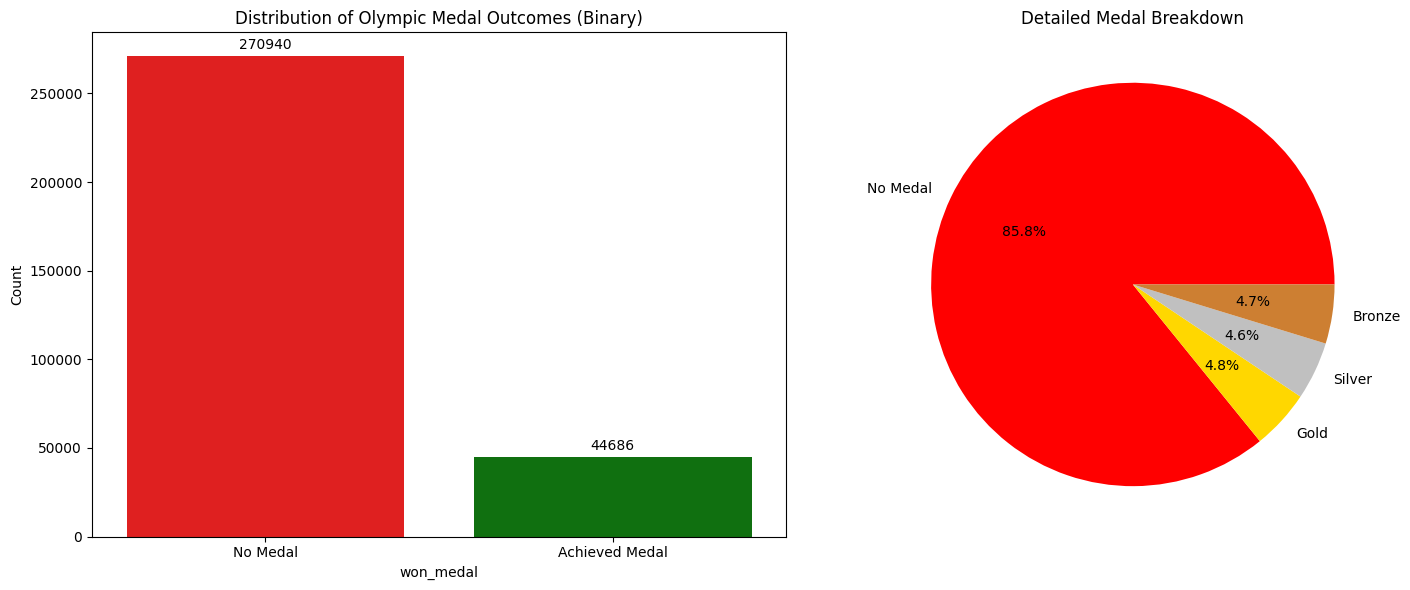

In [30]:
# Lets first fill the missing values in the
global_olympics_df['medal'] = (
    global_olympics_df['medal']
    .fillna('No Medal')
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Count plot of binary target variable (won_medal)
sns.countplot(
    data=global_olympics_df,
    x='won_medal',
    ax=axes[0],
    hue='won_medal',
    legend=False,
    palette=['red', 'green']
)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Medal", "Achieved Medal"])
axes[0].set_title('Distribution of Olympic Medal Outcomes (Binary)')
axes[0].set_ylabel('Count')

# Display the specific counts on top of the bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', label_type='edge', padding=3)

# Percentage pie chart of individual medals
medal_order = ['No Medal', 'Gold', 'Silver', 'Bronze']
counts = global_olympics_df['medal'].value_counts().reindex(medal_order, fill_value=0)
axes[1].pie(counts, labels=medal_order, autopct='%1.1f%%', colors=['red', '#ffd700', '#c0c0c0', '#cd7f32'])
axes[1].set_title('Detailed Medal Breakdown')

plt.tight_layout()
plt.show()

### The Binary Olympic Medal Outcomes Count Plot

The graph showcases a major imbalance between with the No medal having 270940 records containing no medals vs only 44686 records containing medals this showcases an imbalance with an approximate ratio of 6:1

### The Detailed Metal Breakdown

The pie chart showcases the same major imbalance with the portion of achieved metals being almost evenly divided with the following ratio between Gold : Silver : Bronze = 4.8% : 4.6% : 4.7%. Whilst no medal contains 85.8% of the dataset.

Overview: This heavy imbalance indicate that a possible SMOTENC method should be used before training the logistic regression model.

## Showcasing Athlete participation over time

Let's examine how Olympic participation has changed throughout history.
 We will seperate the winter and summer games because the winter games have traditionally lower participation

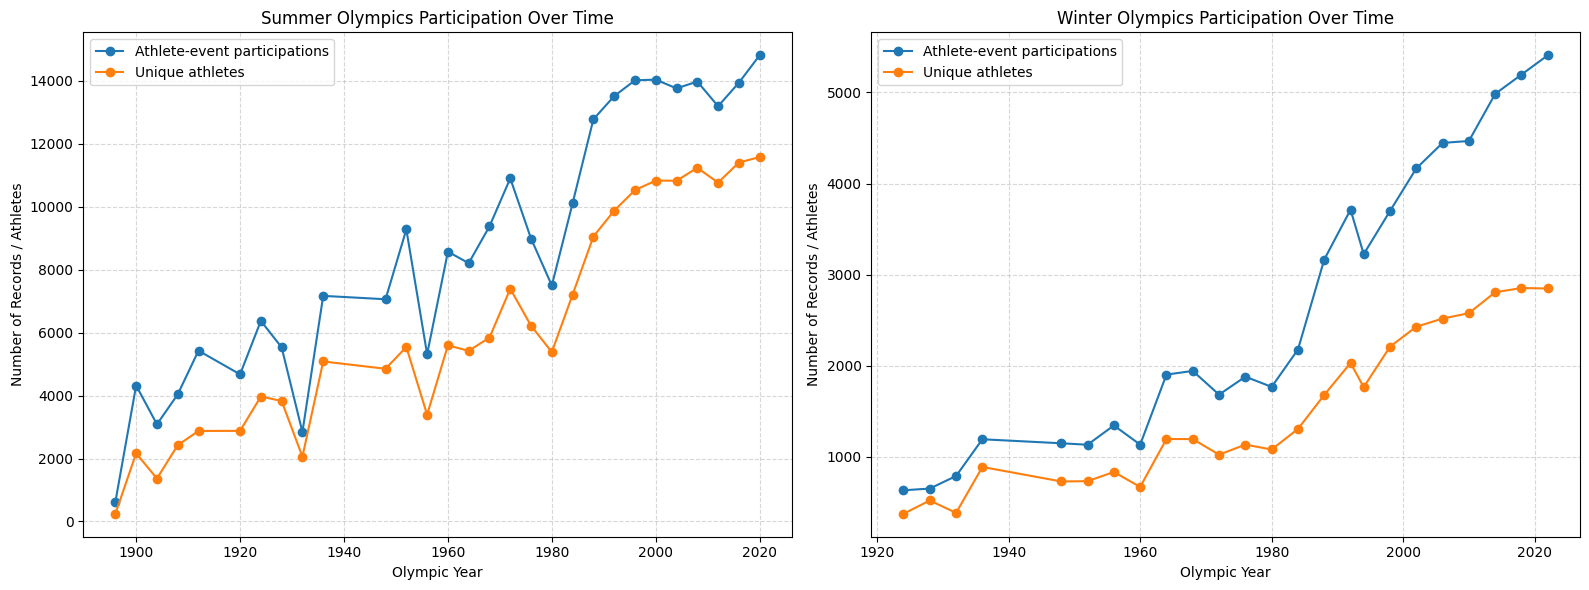

In [31]:
# Filter data for Summer and Winter seasons
summer_df = global_olympics_df[global_olympics_df['season'] == 'Summer']
winter_df = global_olympics_df[global_olympics_df['season'] == 'Winter']

# Calculate metrics for Summer Games
summer_participation = summer_df.groupby('year').size()
summer_unique_athletes = summer_df.groupby('year')['athlete_id'].nunique()

# Calculate metrics for Winter Games
winter_participation = winter_df.groupby('year').size()
winter_unique_athletes = winter_df.groupby('year')['athlete_id'].nunique()

# Set up two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left subplot: Summer Games
axes[0].plot(
    summer_participation.index,
    summer_participation.values,
    marker='o',
    color='tab:blue',
    label='Athlete-event participations'
)
axes[0].plot(
    summer_unique_athletes.index,
    summer_unique_athletes.values,
    marker='o',
    color='tab:orange',
    label='Unique athletes'
)
axes[0].set_title('Summer Olympics Participation Over Time')
axes[0].set_xlabel('Olympic Year')
axes[0].set_ylabel('Number of Records / Athletes')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right subplot: Winter Games
axes[1].plot(
    winter_participation.index,
    winter_participation.values,
    marker='o',
    color='tab:blue',
    label='Athlete-event participations'
)
axes[1].plot(
    winter_unique_athletes.index,
    winter_unique_athletes.values,
    marker='o',
    color='tab:orange',
    label='Unique athletes'
)
axes[1].set_title('Winter Olympics Participation Over Time')
axes[1].set_xlabel('Olympic Year')
axes[1].set_ylabel('Number of Records / Athletes')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Participation graph evaluation
- The amount of participants in both the Summer and Winter games have majorly increased since the the beginning of the Games with the latest recorded games in the dataset (2020 Summer Games, Tokyo and 2022 Winter Games , Beijing).

- The Winter games have had overall less participation than the Summer games. Summer games estimated based on the graph have seen three times more participation. This is probably because the winter games have less events as well as less competing countries.

- There was a decrease in participation in the 1936 Summer Olympics. This was due to a boycott against Nazi Germany which was hosting the event. Another decrease was in the 1956 Summer Games and 1960 Winter Games, this decrease has been theorized to be attributed to the Cold War during this period.

- The Winter Games showcases that a large portion of athletes compete in multiple events. In the latest recorded Winter Olympic Games having participation in events being above 5500 and there being less than 3000 unique competitors. In comparison the latest Summer Games have partitipation above 15000 with around 12000 unique competitors.

## Metal Achievement over time

Line Chart showing the number of medal-winning athlete-event records per Olympic year.

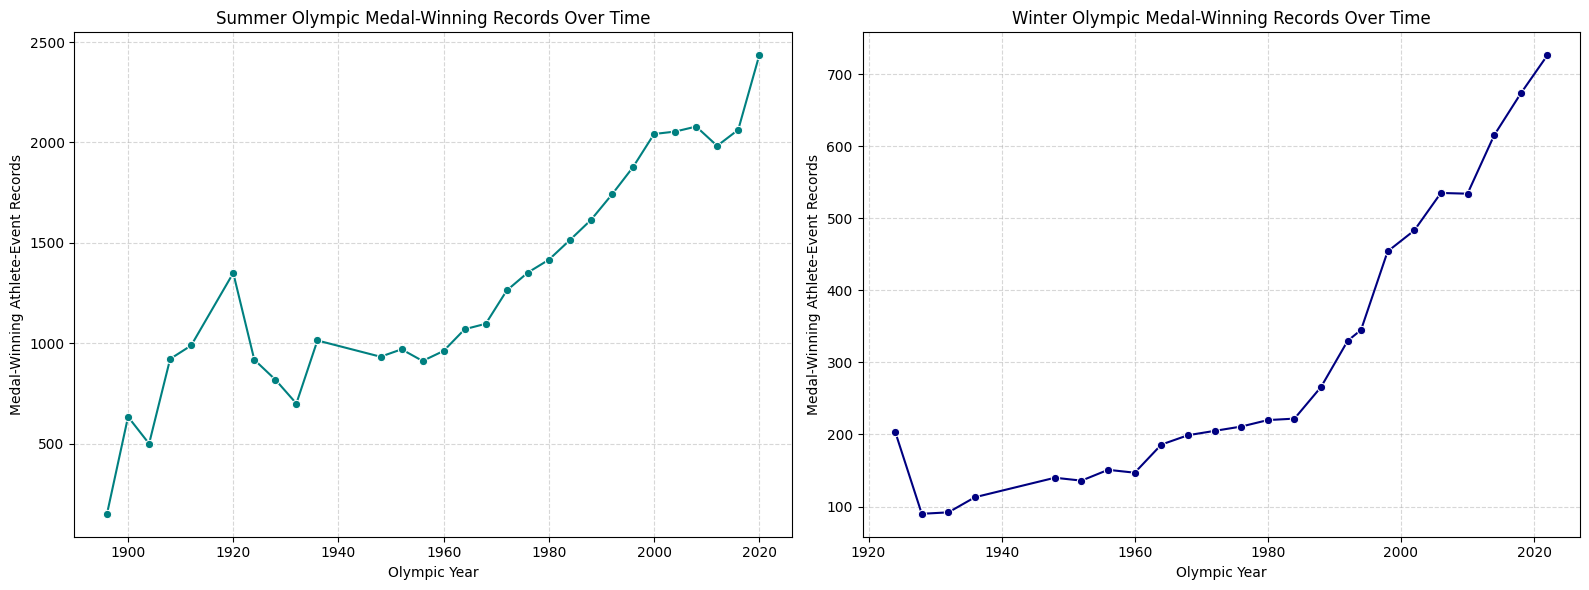

In [32]:
# Filter data for Summer and Winter medalists
summer_medals_df = global_olympics_df[
    (global_olympics_df['won_medal'] == 1) & (global_olympics_df['season'] == 'Summer')
]
winter_medals_df = global_olympics_df[
    (global_olympics_df['won_medal'] == 1) & (global_olympics_df['season'] == 'Winter')
]

# Group by year to get counts
summer_medals_over_time = summer_medals_df.groupby('year').size()
winter_medals_over_time = winter_medals_df.groupby('year').size()

# Set up two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left subplot: Summer Olympics Medals
sns.lineplot(
    x=summer_medals_over_time.index,
    y=summer_medals_over_time.values,
    marker='o',
    ax=axes[0],
    color='teal'
)
axes[0].set_title('Summer Olympic Medal-Winning Records Over Time')
axes[0].set_xlabel('Olympic Year')
axes[0].set_ylabel('Medal-Winning Athlete-Event Records')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right subplot: Winter Olympics Medals
sns.lineplot(
    x=winter_medals_over_time.index,
    y=winter_medals_over_time.values,
    marker='o',
    ax=axes[1],
    color='navy'
)
axes[1].set_title('Winter Olympic Medal-Winning Records Over Time')
axes[1].set_xlabel('Olympic Year')
axes[1].set_ylabel('Medal-Winning Athlete-Event Records')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Graph Evaluation
- Overall trend of both graphs showcases an increase of medals over the years which seems to correlate with the increase of particpation.

- Since the pariticipation in the Winter Games is a about three times less that the Summer games on average we can also see the same trend appearing in the medals over time, however In the 2010 - 2025 there seems to be an expenentiol increase in the Winter Games medal trend which is not present in the Summer Edition.

- In the Summer Games graph there seem to be an unusual medal increase in the 1920 which doesn't specifically correlate with the participation graph. There is also a significant decrease in the 1936 Summer Games which does correlate to the participation boycott.

## Participation by sport

Bar chart which showcases the sports with the highest levels of Olympic participation.

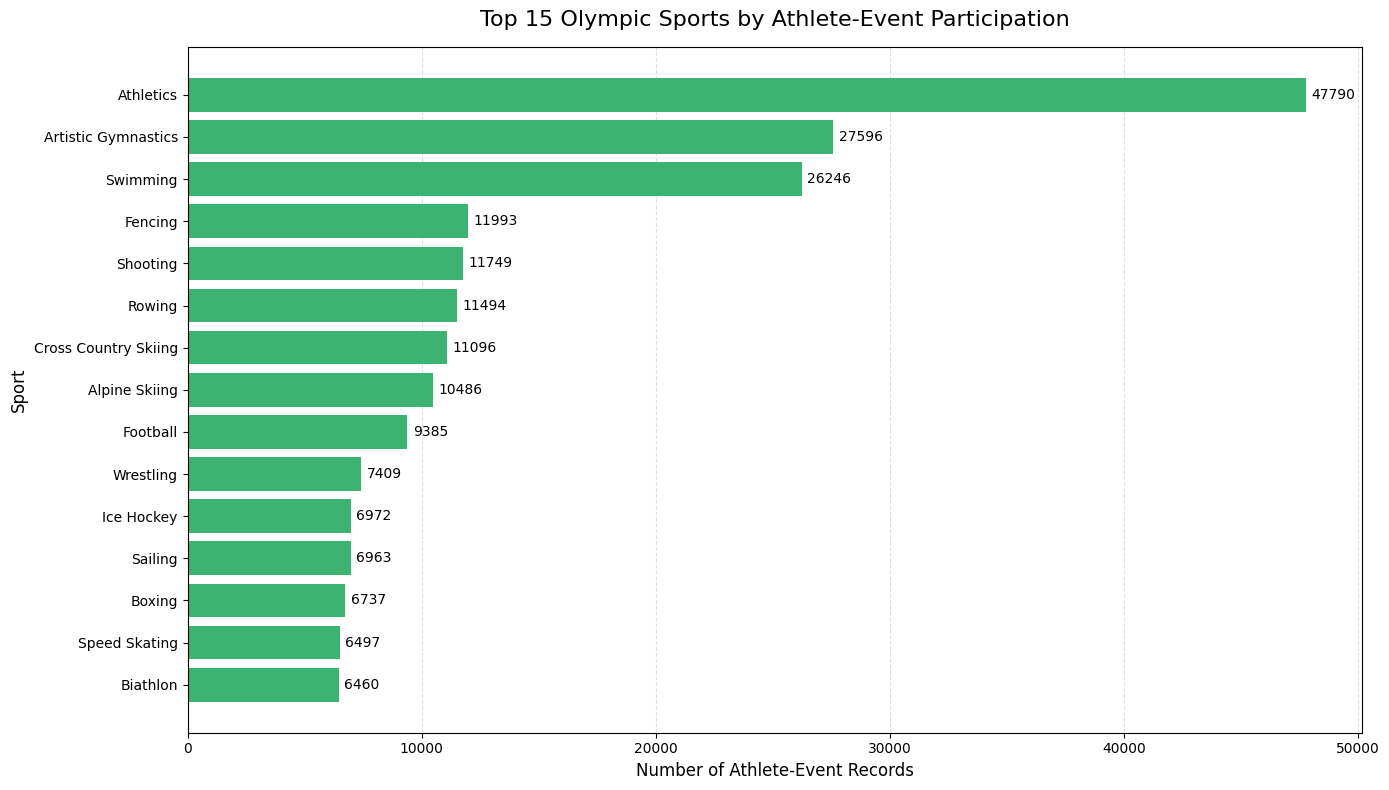

In [33]:
sport_participation = (
    global_olympics_df['sport']
    .value_counts()
    .head(15)
    .sort_values()
)

# Create the horizontal bar chart
plt.figure(figsize=(14, 8))

# Provide both the sport labels (index) and the count values
bars = plt.barh(
    sport_participation.index,
    sport_participation.values,
    color='mediumseagreen'
)

plt.title(
    'Top 15 Olympic Sports by Athlete-Event Participation',
    fontsize=16,
    pad=15
)
plt.xlabel('Number of Athlete-Event Records', fontsize=12)
plt.ylabel('Sport', fontsize=12)

# Label with the exact counts instead of a percentage string format
plt.bar_label(bars, fmt='%d', padding=4)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

### Graph Evaluation

- The highest participated (47790) in sport is athelics which makes sense since it covers a wide array of event categories such as throws, runs and jumps.

- Swimming stands out as the sport containing only one event category with the highest participation which is 26246.

- Luckily the participation across sports doesn't seem to be concentrated to a singular sport which will provide wider data variety across different sports.



## Medals by sports

A bar chart which showcases sports that have historically produced the most medal-winning athlete records.

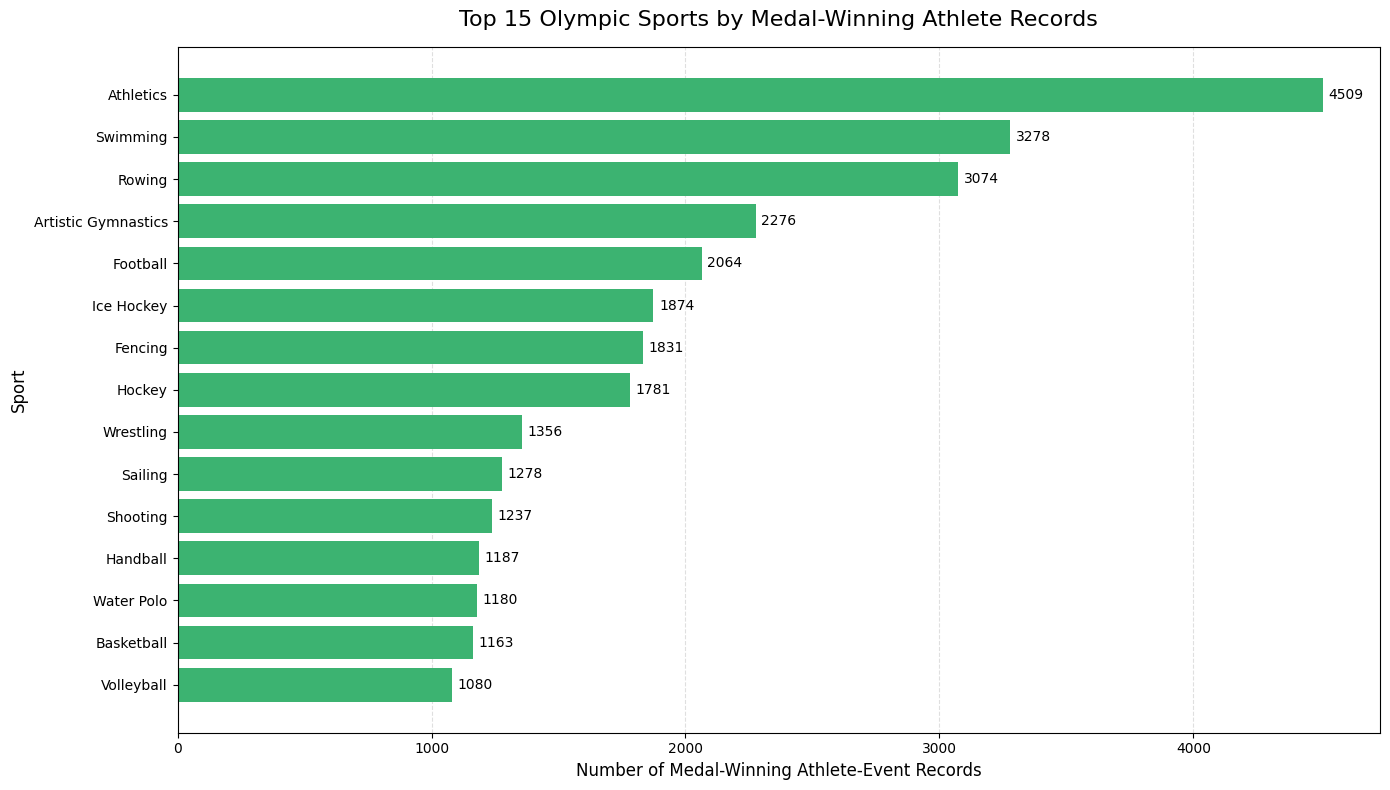

In [34]:
sport_medals = (
    global_olympics_df[
        global_olympics_df['won_medal'] == 1
    ]
    ['sport']
    .value_counts()
    .head(15)
    .sort_values()
)

# Create the horizontal bar chart
plt.figure(figsize=(14, 8))

# Provide both the sport labels (index) and the count values
bars = plt.barh(
    sport_medals.index,
    sport_medals.values,
    color='mediumseagreen'
)

plt.title(
    'Top 15 Olympic Sports by Medal-Winning Athlete Records',
    fontsize=16,
    pad=15
)
plt.xlabel('Number of Medal-Winning Athlete-Event Records', fontsize=12)
plt.ylabel('Sport', fontsize=12)

# Label with the exact counts instead of a percentage string format
plt.bar_label(bars, fmt='%d', padding=4)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


### Graph Evaluation

- The sport with the most medals achieved by athletes correlates to the most participated in sport which is athletics however it has only 4509 medals which is significantly less than the participation (probably due to mass participation in marathons).

- A noticable factor is that the sports which achieved the most medals doesn't directly correlate with the particpation. For example fencing is ranked 4th in participation but is only ranked 7th in the list, Cross Country Skiing is ranked 7th in participation but doesnt even appear on the medals achieved top 15.


## Athlete age distribution

Histogram showcasing the age distribution of Olympic athletes.

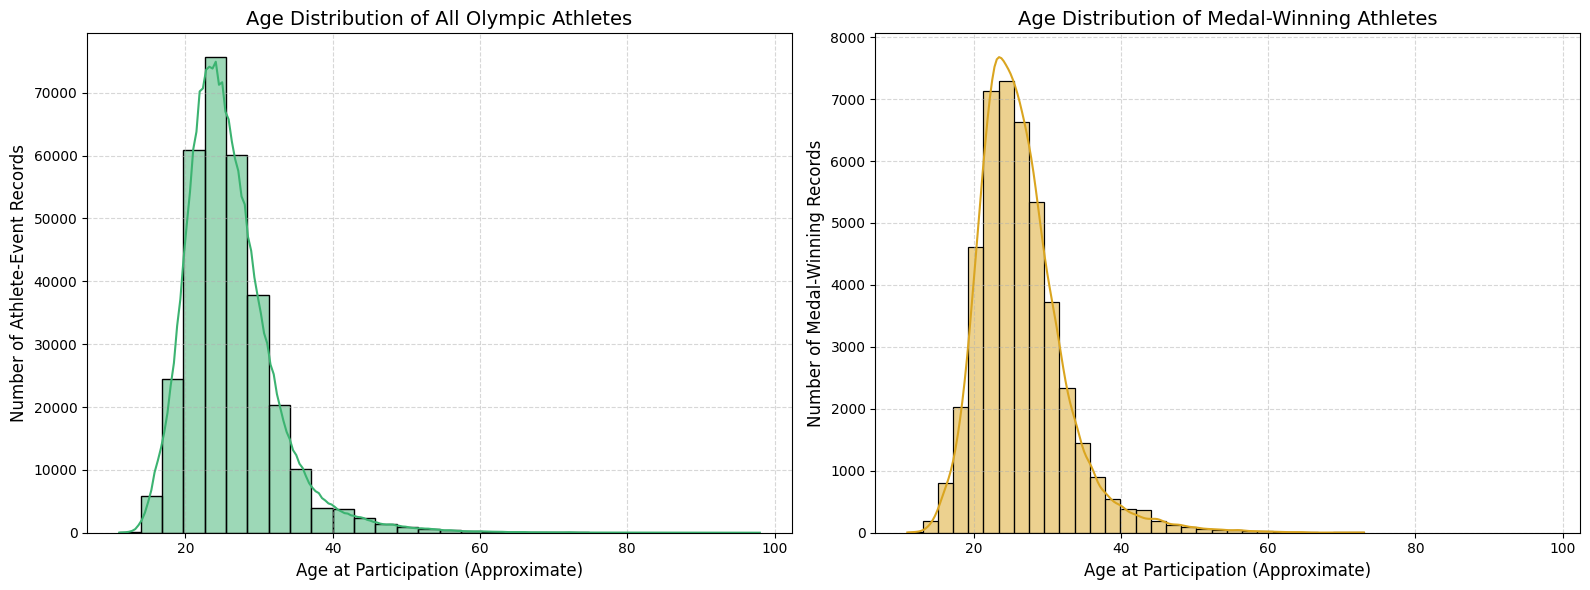

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

# Left plot: All Athletes
sns.histplot(
    data=global_olympics_df,
    x='age',
    bins=30,
    kde=True,
    color='mediumseagreen',
    ax=axes[0]
)
axes[0].set_title('Age Distribution of All Olympic Athletes', fontsize=14)
axes[0].set_xlabel('Age at Participation (Approximate)', fontsize=12)
axes[0].set_ylabel('Number of Athlete-Event Records', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right plot: Medal Winners Only
sns.histplot(
    data=global_olympics_df[global_olympics_df['won_medal'] == 1],
    x='age',
    bins=30,
    kde=True,
    color='goldenrod',
    ax=axes[1]
)
axes[1].set_title('Age Distribution of Medal-Winning Athletes', fontsize=14)
axes[1].set_xlabel('Age at Participation (Approximate)', fontsize=12)
axes[1].set_ylabel('Number of Medal-Winning Records', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Graph Evaluation

- Majority of the athles are in there 20's and early 30's

- The age distribution is focused between the 20 - 40 age range with known outliers of 80 and 90 year olds which competed in the art competitions.

- The medal-winning athlete distribution seems similar to the general age distribution with a slight increase in athletes in there early 20's


### Male versus female participation

A bar chart which showcases the distribution of male and female Olympic participation.

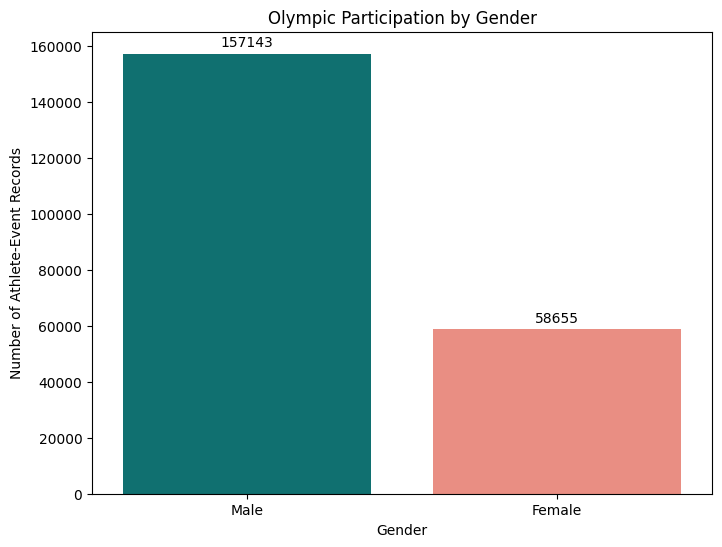

In [36]:
gender_participation = (
   global_olympics_df
    .drop_duplicates(subset=['athlete_id', 'edition_id'])
    ['sex']
    .value_counts()
)

plt.figure(figsize=(8, 6))

# Create the bar plot mapping x to hue to avoid the deprecation warning
ax = sns.barplot(
    x=gender_participation.index,
    y=gender_participation.values,
    hue=gender_participation.index,
    palette={'Male': 'teal', 'Female': 'salmon'},
    legend=False
)

# Add count labels on top of all bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Olympic Participation by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Athlete-Event Records')

plt.show()

- Overall there is a noticable difference between female/male class distribution with Male having 157143 unique participants and Female having 58655. Which is an approximaately a ratio of 2.69 : 1

Let's view the distribution of the gender overtime using a line graph

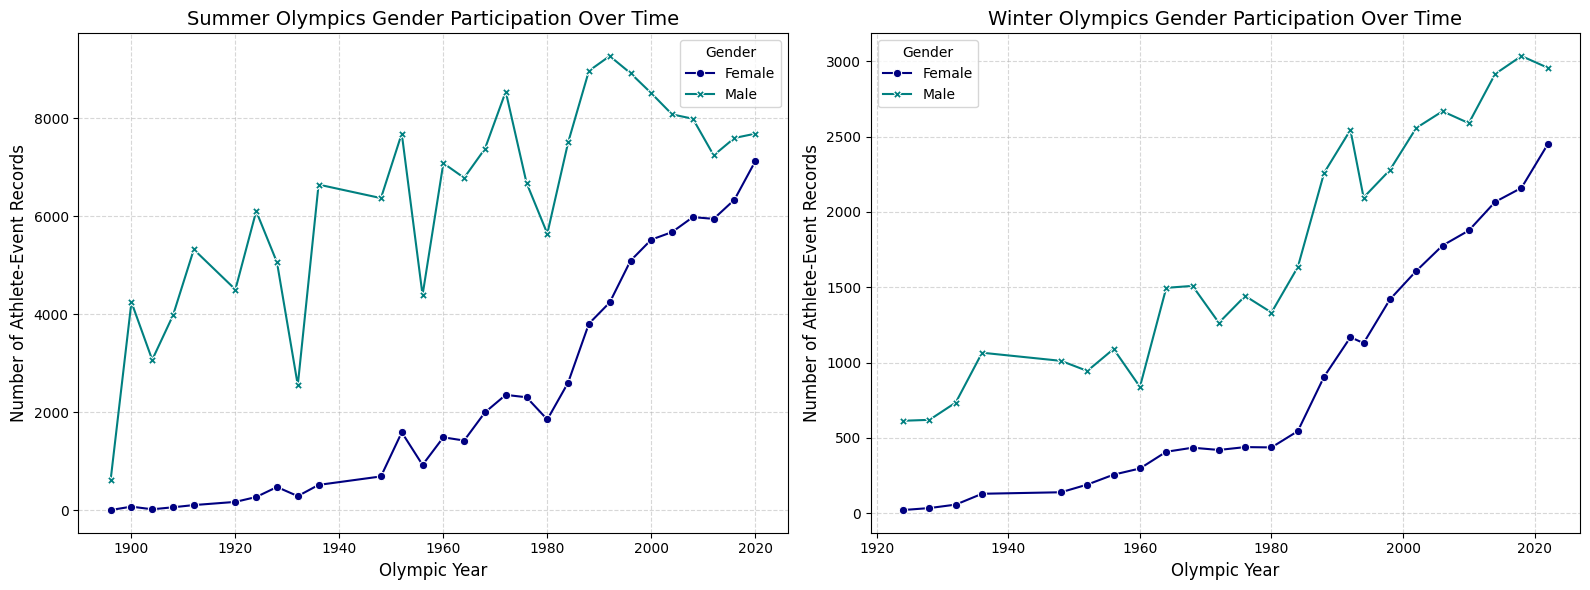

In [37]:
# Group by season, year, and gender to calculate participation counts
summer_gender = (
    global_olympics_df[global_olympics_df['season'] == 'Summer']
    .groupby(['year', 'sex'])
    .size()
    .unstack(fill_value=0)
)

winter_gender = (
    global_olympics_df[global_olympics_df['season'] == 'Winter']
    .groupby(['year', 'sex'])
    .size()
    .unstack(fill_value=0)
)

# Set up two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left subplot: Summer Games Gender Distribution
sns.lineplot(data=summer_gender, markers=True, dashes=False, palette={'Male': 'teal', 'Female': 'navy'}, ax=axes[0])
axes[0].set_title('Summer Olympics Gender Participation Over Time', fontsize=14)
axes[0].set_xlabel('Olympic Year', fontsize=12)
axes[0].set_ylabel('Number of Athlete-Event Records', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Gender')

# Right subplot: Winter Games Gender Distribution
sns.lineplot(data=winter_gender, markers=True, dashes=False, palette={'Male': 'teal', 'Female': 'navy'}, ax=axes[1])
axes[1].set_title('Winter Olympics Gender Participation Over Time', fontsize=14)
axes[1].set_xlabel('Olympic Year', fontsize=12)
axes[1].set_ylabel('Number of Athlete-Event Records', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Gender')

plt.tight_layout()
plt.show()

### Graph Evaluation

- There were minimal participation by female athletes in the early 1900's.

- From the 1980's there have been a visible exponential increase in participation from female athletes.

- This showcases a more balanced Gender ratio for recently held Olympic Games.

## South African VS Global medal proportions

Bar Chart comparing the medal-winning proportions of South African athletes with those of other Olympic participants.

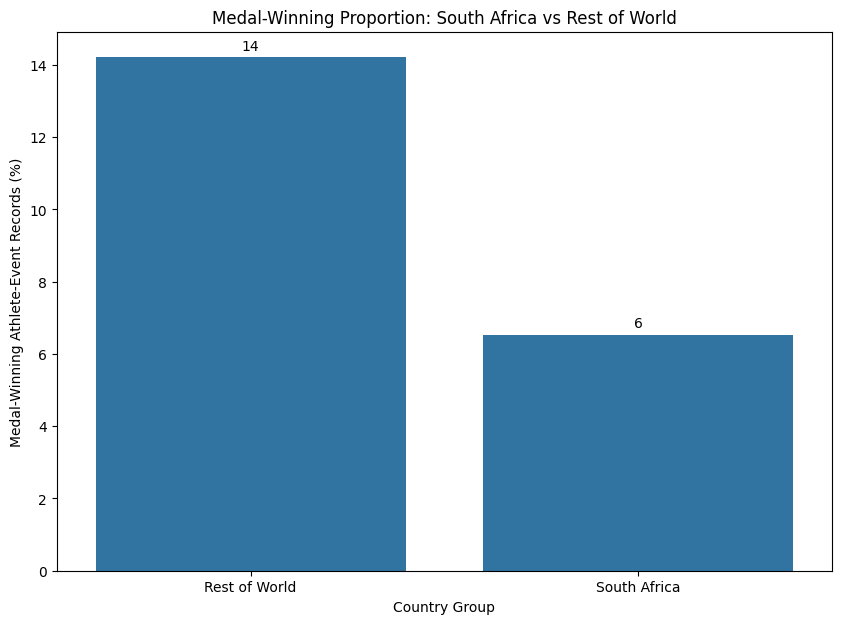

,won_medal
comparison_group,
Rest of World,14.208217
South Africa,6.528046


In [38]:
# Create comparison groups
global_olympics_df['comparison_group'] = np.where(
    global_olympics_df['country_noc'] == 'RSA',
    'South Africa',
    'Rest of World'
)

# Calculate medal-winning proportions
medal_comparison = (
    global_olympics_df
    .groupby('comparison_group')['won_medal']
    .mean() * 100
)

plt.figure(figsize=(10, 7))

ax =sns.barplot(
    x=medal_comparison.index,
    y=medal_comparison.values
)

# Add count labels on top of all bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Medal-Winning Proportion: South Africa vs Rest of World')
plt.xlabel('Country Group')
plt.ylabel('Medal-Winning Athlete-Event Records (%)')

plt.show()

display(medal_comparison)

### Graph evaluation

- On average athletes participating from the rest of the world has a higher likelihood of winning a medal comparitive to South Africa

- Out of all historical South African athlete-event entries in the database, approximately 6.53% resulted in a medal comparitive to individual athlete-event entries for all other nations being approximately 14.21%.

- This is an approximate difference of 7.68% which could indicate a performance gap for South Africa

### South African Athletes medal's won by sport

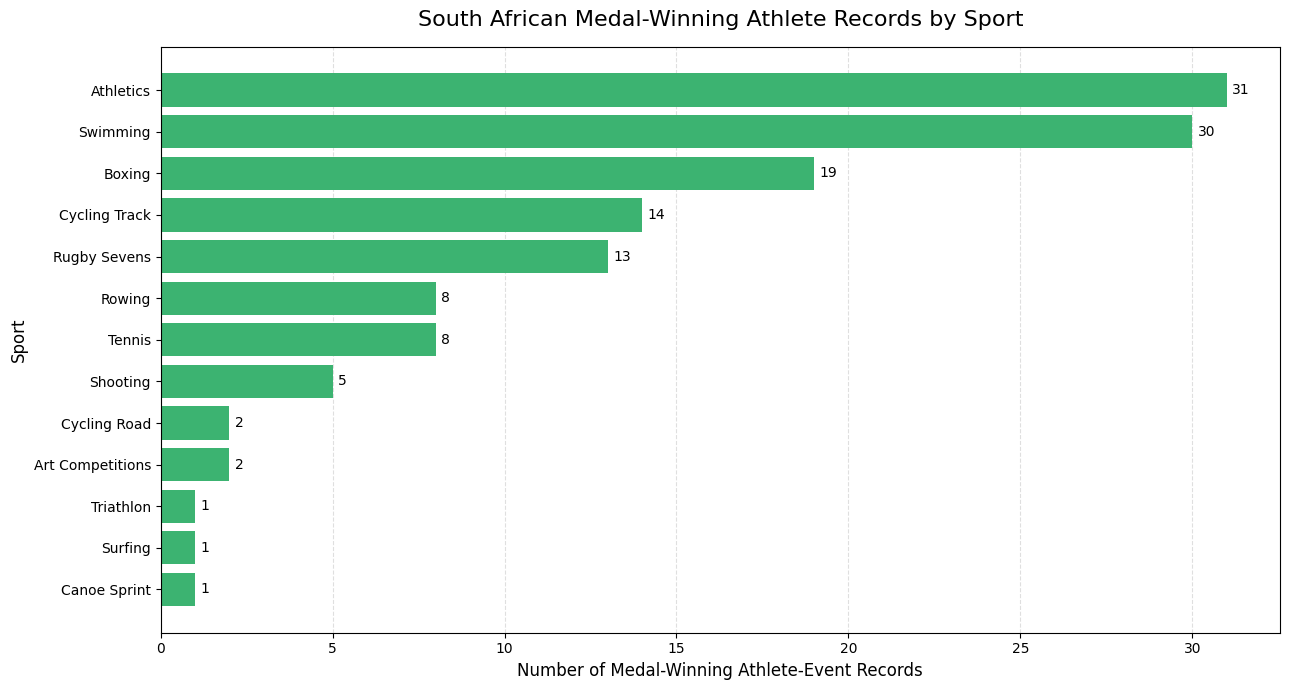

In [39]:
rsa_sport_medals = (
    rsa_df[rsa_df['won_medal'] == 1]
    ['sport']
    .value_counts()
    .sort_values()
)

# Create the horizontal bar chart
plt.figure(figsize=(13, 7))

# Provide both the sport labels (index) and the count values
bars = plt.barh(
    rsa_sport_medals.index,
    rsa_sport_medals.values,
    color='mediumseagreen'
)

plt.title(
    'South African Medal-Winning Athlete Records by Sport',
    fontsize=16,
    pad=15
)
plt.xlabel('Number of Medal-Winning Athlete-Event Records', fontsize=12)
plt.ylabel('Sport', fontsize=12)

# Label with the exact counts instead of a percentage string format
plt.bar_label(bars, fmt='%d', padding=4)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

South Africa has won the most medals in Athletics and Swimming

## South African medal yield by sport

In [40]:
rsa_sport_yield = (
    rsa_df
    .groupby('sport')
    .agg(
        participations=('won_medal', 'count'),
        medal_records=('won_medal', 'sum')
    )
)

# Correctly calculate the medal yield percentage
rsa_sport_yield['medal_yield'] = (
    rsa_sport_yield['medal_records'] /
    rsa_sport_yield['participations'] * 100
)

# Filter for at least 10 participations and more than 0 medal records
rsa_sport_yield = rsa_sport_yield[
    (rsa_sport_yield['participations'] >= 10) &
    (rsa_sport_yield['medal_records'] > 0)
]

display(
    rsa_sport_yield.sort_values(
        'medal_yield',
        ascending=False
    )
)

,participations,medal_records,medal_yield
sport,,,
Rugby Sevens,26,13,50.000000
Boxing,76,19,25.000000
Cycling Track,72,14,19.444444
Art Competitions,12,2,16.666667
Tennis,53,8,15.094340
Rowing,73,8,10.958904
Swimming,324,30,9.259259
Triathlon,16,1,6.250000
Athletics,513,31,6.042885


### Yield Evaluation

- Rugby Sevens has the highest yield with only having 26 participations with half of them resulting the medals being won.

- Athletics has the most participations(513) and medals won(31) but only achieved a total yield of approximately 6.04%  

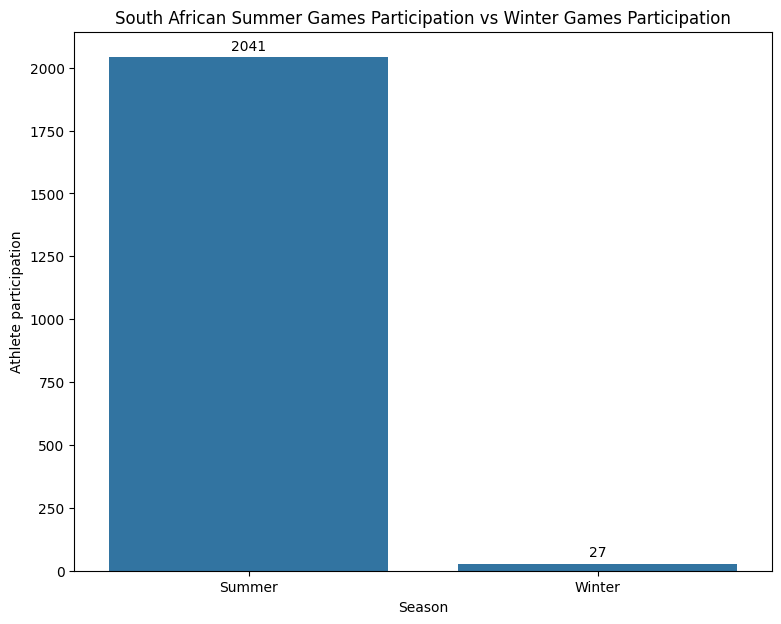

In [41]:
# Count athlete participation per season
rsa_season_participation = (
    rsa_df
    .groupby('season')
    .size()
    .reset_index(name='athlete_count')
)

plt.figure(figsize=(9, 7))

ax = sns.barplot(
    data=rsa_season_participation,
    x='season',
    y='athlete_count'
)

# Add count labels on top of all bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('South African Summer Games Participation vs Winter Games Participation')
plt.xlabel('Season')
plt.ylabel('Athlete participation')

plt.show()


This graph shows that South Africa has only have 27 recorded participations in Winter Olympic Games comparitive to the Summer Games. Which indicates that it might be more beneficial to only use Summer Games records in the initial modeling.

## Feature Engineering /  Predictive feature selection

Let's add and transform two predictive variables based on the provided data that is backed by the EDA.

- `is_host_country` will be a binary value which determines whether the participating athlete is competing in an event/ edition hosted in there country.

- `previous_olympic_participation` is a numerical variable which displays the amount of times an athlete has previously participated.

- `previous_medal achievement` is a numerical variable which displays the amount of times an athlete has previously won medals.

 **Note**: Based on the EDA, we may need to exclude the winter games from the first models because the Summer and Winter Games have different participation levels and sports. A Combination of the Summer and Winter Games could introduce additional differences that make the model harder to interpret. It should also be noted that South Africa has a very small amount of Winter Games participation which might devalue the need to add the Winter Games.

In [42]:
# Creation of a copy of the global dataset
model_df = global_olympics_df.copy()

# Keep Summer Olympic records for the initial model
model_df = model_df[
    model_df['season'] == 'Summer'
].copy()

# Creation of a host-country indicator
model_df['is_host_country'] = (
    model_df['country_noc'] ==
    model_df['host_country_noc']
).astype(int)

# Creation of the previous_olympic_participation and previous_medal_achievement

# Creating a temp df which contains one record per athlete per Olympic edition
athlete_history = (
    model_df
    .groupby(
        ['athlete_id', 'edition_id', 'year'],
        as_index=False
    )
    .agg(
        won_medal_in_edition=('won_medal', 'max')
    )
)

# Sort the temp df chronologically
athlete_history = athlete_history.sort_values(
    ['athlete_id', 'year']
)

# Count previous Olympic appearances
athlete_history['previous_olympic_participation'] = (
    athlete_history
    .groupby('athlete_id')
    .cumcount()
)

# Count previous medal-winning editions
athlete_history['previous_medal_achievement'] = (
    athlete_history
    .groupby('athlete_id')['won_medal_in_edition']
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

# Merge the historical features back into the event-level dataset
model_df = model_df.merge(
    athlete_history[
        [
            'athlete_id',
            'edition_id',
            'previous_olympic_participation',
            'previous_medal_achievement'
        ]
    ],
    on=['athlete_id', 'edition_id'],
    how='left',
    validate='many_to_one'
)

# Check the dataset
print("Dataset shape:", model_df.shape)

print("\nTarget distribution:")
print(model_df['won_medal'].value_counts())

print("\nMissing values:")
print(model_df[
    ['age', 'sex', 'sport', 'event', 'previous_medal_achievement',
     'isTeamSport', 'year', 'is_host_country', 'previous_olympic_participation', 'won_medal' ]
].isnull().sum())

# Verify the new features
display(
    model_df[
        [
            'athlete',
            'year',
            'is_host_country',
            'previous_olympic_participation',
            'previous_medal_achievement',
            'won_medal'
        ]
    ].head(50)
)

Dataset shape: (253450, 32)

Target distribution:
won_medal
0    216077
1     37373
Name: count, dtype: int64

Missing values:
age                               5304
sex                                  7
sport                                0
event                                0
previous_medal_achievement           0
isTeamSport                          0
year                                 0
is_host_country                      0
previous_olympic_participation       0
won_medal                            0
dtype: int64


,athlete,year,is_host_country,previous_olympic_participation,previous_medal_achievement,won_medal
0,Ernest Hutcheon,1908,0,0,0.0,0
1,Henry Murray,1908,0,0,0.0,0
2,Harvey Sutton,1908,0,0,0.0,0
3,Guy Haskins,1908,0,0,0.0,0
4,Joseph Lynch,1908,0,0,0.0,0
5,Henry Murray,1908,0,0,0.0,0
6,Joseph Lynch,1908,0,0,0.0,0
7,Charles Swain,1908,0,0,0.0,0
8,Guy Haskins,1908,0,0,0.0,0
9,George Blake,1908,0,0,0.0,0


### Model Dataframe evaluation

In [43]:
# Check the dataset
print("Dataset shape:", model_df.shape)

print("\nTarget distribution:")
print(model_df['won_medal'].value_counts())

print("\nMissing values:")
print(model_df[
    ['age', 'sex', 'sport', 'event', 'previous_medal_achievement',
     'isTeamSport', 'year', 'is_host_country', 'previous_olympic_participation', 'won_medal' ]
].isnull().sum())

# Verify the new features by showing records past the first few years (e.g., from 1920 onwards)
# This helps us verify that returning athletes have non-zero historical metrics.
print("\nVerifying features for records from 1920 onwards:")
display(
    model_df[
        model_df['year'] >= 1920
    ][
        [
            'athlete',
            'year',
            'is_host_country',
            'previous_olympic_participation',
            'previous_medal_achievement',
            'won_medal'
        ]
    ].sort_values(['previous_olympic_participation', 'year'], ascending=[False, True]).head(10)
)

Dataset shape: (253450, 32)

Target distribution:
won_medal
0    216077
1     37373
Name: count, dtype: int64

Missing values:
age                               5304
sex                                  7
sport                                0
event                                0
previous_medal_achievement           0
isTeamSport                          0
year                                 0
is_host_country                      0
previous_olympic_participation       0
won_medal                            0
dtype: int64

Verifying features for records from 1920 onwards:


,athlete,year,is_host_country,previous_olympic_participation,previous_medal_achievement,won_medal
94338,Ian Millar,2012,0,9,1.0,0
94345,Ian Millar,2012,0,9,1.0,0
52102,Hubert Raudaschl,1996,0,8,2.0,0
93916,Ian Millar,2008,0,8,0.0,0
93920,Ian Millar,2008,0,8,0.0,1
66503,Afanasijs Kuzmins,2012,0,8,2.0,0
15046,Nino Salukvadze,2020,0,8,2.0,0
15047,Nino Salukvadze,2020,0,8,2.0,0
47514,Paul Elvstrøm,1988,0,7,4.0,0
130186,Durward Knowles,1988,0,7,2.0,0


The new variables were successfully created.

The amount of records decreased from 315626 to 253450 after filtering to only include the Summer Games seasons.

## Correlation analysis

Let's view the Correlation of the variables before our final feature selection

### Correlation with the target variable

Correlation Matrix which showcases the correlation between the numerical features.

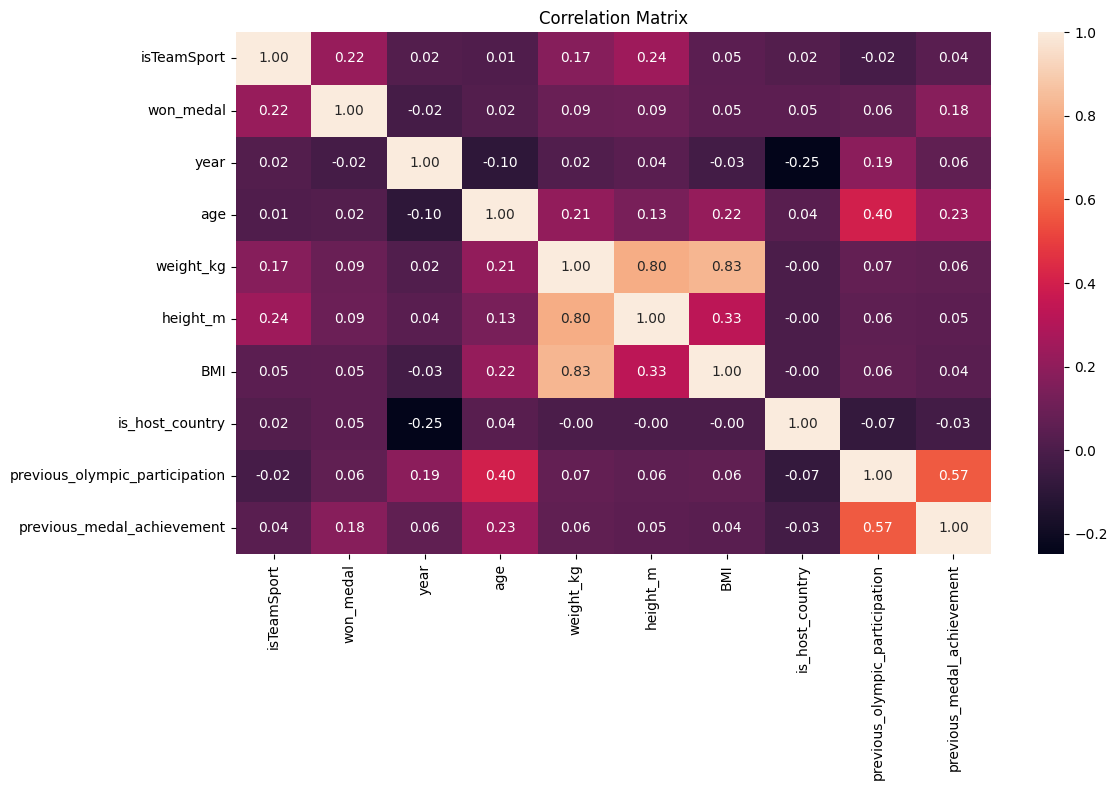

In [44]:
excluded_cols = ['edition_id', 'athlete_id', 'result_id', 'height','birth_year']

corr_matrix = (
    model_df
    .drop(columns=excluded_cols, errors='ignore')
    .corr(numeric_only=True)
)
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,        # show the correlation values inside each cell
    fmt='.2f',

)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Correlation Matrix Evaluation

#### Target Relationships

- isTeamSport (r = 0.22) is the Strongest positive linear relationship with winning a medal.

-  previous_medal_achievement (r = 0.18): Second strongest predictor. Prior success shows a meaningful positive correlation with winning another medal.

- weight_kg (0.09), height_m (0.09), previous_olympic_participation (0.06), is_host_country (0.05), BMI (0.05), and age (0.02) demonstrate very weak individual linear correlations with the target.  

- year (r = -0.02): Showcases a weak negative relationship with winning a medal.   

- Overall there is no particular predictive variable which showcases a strong positive linear relationship with winning a medal. Meaning multiple different features together will help predict the target variable.

####Notable Multicollinearity Risks

- weight_kg, height_m, and BMI naturally had a high correlation but won't be used in the initial model since it has a high amount of missing records.

- previous_olympic_participation and previous_medal_achievement r = 0.57. Athletes who have participated in past Olympics are naturally more likely to have won past medals.

- age vs. previous_olympic_participation: r = 0.40, age vs. previous_medal_achievement: r = 0.23. This correlation could indicate that older athletes generally accumulate more past games and medals.

Evaluating the matrix showcases that there is no current need to remove the any predictive features in the current model but in future models where I might choose to use the BMI and impute values I should remove the weight_kg and height_m.

### Variance Inflation Factor (VIF) Calculations

VIF measures how strongly a numerical predictor can be explained by the other predictors.

This is particularly relevant to Logistic Regression because high multicollinearity can make its coefficients unstable and difficult to interpret.

In [45]:
# Select numerical predictors
vif_features = [
    'age',
    'year',
    'is_host_country',
    'previous_olympic_participation',
    'previous_medal_achievement',
    'isTeamSport'

]

# Prepare data for VIF
vif_df = model_df[vif_features].copy()

# Handle missing values
vif_df = vif_df.fillna(vif_df.median())

# Calculate VIF
vif_results = pd.DataFrame()

vif_results['Feature'] = vif_df.columns

vif_results['VIF'] = [
    variance_inflation_factor(
        vif_df.values, i
    )
    for i in range(vif_df.shape[1])
]

vif_results = vif_results.sort_values(
    by='VIF',
    ascending=False
)

display(vif_results)

,Feature,VIF
3,previous_olympic_participation,1.773342
4,previous_medal_achievement,1.492934
0,age,1.230311
1,year,1.138098
2,is_host_country,1.068515
5,isTeamSport,1.006288


Standard Threshold Benchmarks:
- $\text{VIF} = 1$: Completely un-correlated with other predictors.
- $1 < \text{VIF} < 2.5$: Low correlation; safe for linear models without regularisation.
- $\text{VIF} \ge 5$ or $10$: Severe multicollinearity requiring feature removal or reduction.

Using the benchmark above it is noticible that the dataset has no multicollinearity Risk since the VIF scores ranges from $1.006 - 1.77$

## Final Feature selection

In [46]:
# Numeric features
numeric_features = [
    'age',
    'year',
    'is_host_country',
      'previous_olympic_participation',
    'previous_medal_achievement'
]

# Categorical features
categorical_features = [
    'sex',
    'sport',
    'event',
    'isTeamSport'
]

# Combine the feature names
feature_columns = (
    numeric_features + categorical_features
)

# Create X and y
X = model_df[feature_columns].copy()
y = model_df['won_medal'].copy()

print("Predictive features:", feature_columns)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(model_df.head())

Predictive features: ['age', 'year', 'is_host_country', 'previous_olympic_participation', 'previous_medal_achievement', 'sex', 'sport', 'event', 'isTeamSport']
X shape: (253450, 9)
y shape: (253450,)


,edition,edition_id,country_noc,sport,event,result_id,athlete,athlete_id,pos,medal,...,birth_year,age,weight_kg,height_m,BMI,season,comparison_group,is_host_country,previous_olympic_participation,previous_medal_achievement
0,1908 Summer Olympics,5,ANZ,Athletics,"100 metres, Men",56265,Ernest Hutcheon,64710,DNS,No Medal,...,1889,19,NaN,NaN,NaN,Summer,Rest of World,0,0,0.0
1,1908 Summer Olympics,5,ANZ,Athletics,"400 metres, Men",56313,Henry Murray,64756,DNS,No Medal,...,1886,22,NaN,NaN,NaN,Summer,Rest of World,0,0,0.0
2,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Harvey Sutton,64808,3 h8 r1/2,No Medal,...,1882,26,NaN,NaN,NaN,Summer,Rest of World,0,0,0.0
3,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Guy Haskins,922519,DNS,No Medal,...,1883,25,NaN,NaN,NaN,Summer,Rest of World,0,0,0.0
4,1908 Summer Olympics,5,ANZ,Athletics,"800 metres, Men",56338,Joseph Lynch,64735,DNS,No Medal,...,1878,30,NaN,NaN,NaN,Summer,Rest of World,0,0,0.0


##Creating the South African modelling dataset

In [47]:
# Filter the global modelling dataset to South African records
rsa_model_df = model_df[
    model_df['country_noc'] == 'RSA'
].copy()

print("South African modelling dataset shape:", rsa_model_df.shape)

print("\nTarget distribution:")
print(rsa_model_df['won_medal'].value_counts())

print("\nTarget percentages:")
print(rsa_model_df['won_medal'].value_counts(normalize=True) * 100)

print("\nRecords per Olympic year:")
print(rsa_model_df.groupby('year').size())

South African modelling dataset shape: (2041, 32)

Target distribution:
won_medal
0    1906
1     135
Name: count, dtype: int64

Target percentages:
won_medal
0    93.385595
1     6.614405
Name: proportion, dtype: float64

Records per Olympic year:
year
1904      9
1908     60
1912     71
1920    106
1924     62
1928     57
1932     24
1936     50
1948     44
1952    117
1956     96
1960     74
1992    143
1996    112
2000    170
2004    130
2008    187
2012    154
2016    166
2020    209
dtype: int64


In [48]:
# Numerical features for South Africa
numeric_features_rsa = [
    'age',
    'year',
    'previous_olympic_participation',
    'previous_medal_achievement'
]

# Categorical features for South Africa
categorical_features_rsa = [
    'sex',
    'sport',
    'event',
    'isTeamSport'
]

rsa_feature_columns = (
    numeric_features_rsa + categorical_features_rsa
)

# Create X and y
X_rsa = rsa_model_df[rsa_feature_columns].copy()
y_rsa = rsa_model_df['won_medal'].copy()

print("RSA predictive features:", rsa_feature_columns)
print("X shape:", X_rsa.shape)
print("y shape:", y_rsa.shape)

RSA predictive features: ['age', 'year', 'previous_olympic_participation', 'previous_medal_achievement', 'sex', 'sport', 'event', 'isTeamSport']
X shape: (2041, 8)
y shape: (2041,)


### Let's Split the data before encoding:

The main reason to split the data before encoding is to prevent data leakage.

When you encode categorical variables or calculate values for imputation and scaling, the preprocessing methods learn information from the data.

For example, consider the sport feature. Your training data might contain:
- Athletics
- Swimming
- Rowing
- Gymnastics

Your test data might also contain a sport that was not present in the training data.

If you encode the entire dataset before splitting, the encoder has already seen the categories in the test set. This means information from the test set has influenced the preprocessing process.

The same issue applies to:
- Imputation: calculating the median using both training and test data.
- Scaling: calculating the mean and standard deviation using both datasets.
- Encoding: learning categories from both datasets.
- SMOTENC: generating synthetic observations using the test data, which must never happen.

The important principle is that the test set should represent genuinely unseen data.

**Diagram provided by ChatGPT to explain the proccess**

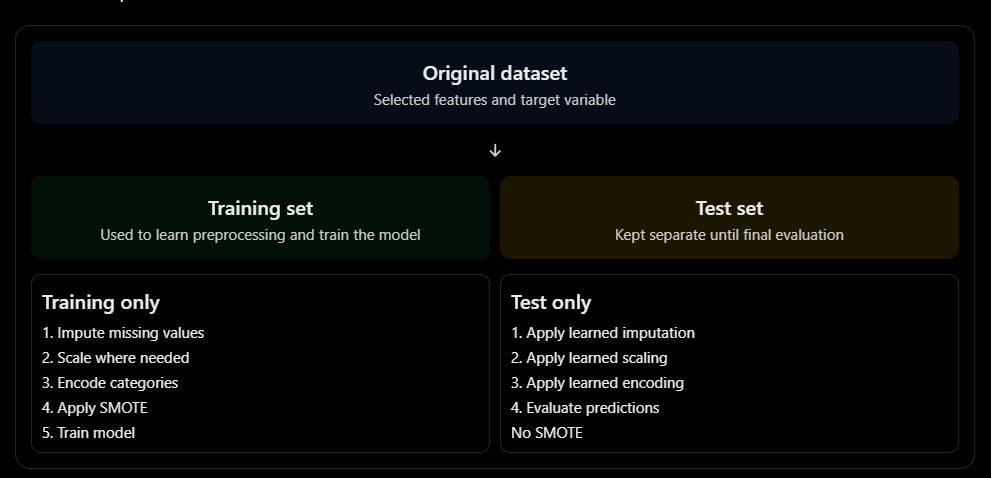

## Train / Test split

This model should test whether the model can predict results from a later Olympic edition using information from earlier editions.

Therefore a random split would mix older and newer Olympic results across training and testing. That could make the model's performance look better than it really is.

Therefore in the initial models we will reserve the latest two Summer Olympic years in the dataset for testing.

## Split the Global Dataset

In [49]:
# Identify the latest two Olympic years
available_years = sorted(model_df['year'].unique())

test_years = available_years[-2:]

print("Test years:", test_years)

# Chronological split
train_mask = ~model_df['year'].isin(test_years)
test_mask = model_df['year'].isin(test_years)

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining years:")
print(model_df.loc[train_mask, 'year'].unique())

print("\nTesting years:")
print(model_df.loc[test_mask, 'year'].unique())

Test years: [np.int64(2016), np.int64(2020)]
Training records: 224693
Testing records: 28757

Training years:
[1908 1912 1900 1988 1992 1996 2000 2004 2008 2012 1984 1976 1972 1980
 1968 1936 1948 1956 1960 1964 1952 1932 1924 1920 1928 1904 1896]

Testing years:
[2016 2020]


Training records: 224693
Testing records: 28757

Training years:
[1908 1912 1900 1988 1992 1996 2000 2004 2008 2012 1984 1976 1972 1980
 1968 1936 1948 1956 1960 1964 1952 1932 1924 1920 1928 1904 1896]

Testing years:
[2016 2020]

## Split the South African dataset

In [50]:
# Use the same test years as the global model
rsa_test_years = [2016, 2020]

rsa_train_mask = ~rsa_model_df['year'].isin(rsa_test_years)
rsa_test_mask = rsa_model_df['year'].isin(rsa_test_years)

X_train_rsa = X_rsa.loc[rsa_train_mask].copy()
X_test_rsa = X_rsa.loc[rsa_test_mask].copy()

y_train_rsa = y_rsa.loc[rsa_train_mask].copy()
y_test_rsa = y_rsa.loc[rsa_test_mask].copy()

print("RSA training records:", len(X_train_rsa))
print("RSA testing records:", len(X_test_rsa))

print("\nRSA training target distribution:")
print(y_train_rsa.value_counts())

print("\nRSA testing target distribution:")
print(y_test_rsa.value_counts())

print("\nRSA testing years:")
print(rsa_model_df.loc[rsa_test_mask, 'year'].unique())

RSA training records: 1666
RSA testing records: 375

RSA training target distribution:
won_medal
0    1557
1     109
Name: count, dtype: int64

RSA testing target distribution:
won_medal
0    349
1     26
Name: count, dtype: int64

RSA testing years:
[2016 2020]


### Handling the class imbalance of the target variable

In [51]:
print("Training set class distribution:")
print(y_train.value_counts())

print("\nTraining set class percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training set class distribution:
won_medal
0    191817
1     32876
Name: count, dtype: int64

Training set class percentages:
won_medal
0    85.368481
1    14.631519
Name: proportion, dtype: float64


In [52]:
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTraining feature columns:")
print(X_train.columns.tolist())

Numerical features: ['age', 'year', 'is_host_country', 'previous_olympic_participation', 'previous_medal_achievement']
Categorical features: ['sex', 'sport', 'event', 'isTeamSport']

Training feature columns:
['age', 'year', 'is_host_country', 'previous_olympic_participation', 'previous_medal_achievement', 'sex', 'sport', 'event', 'isTeamSport']


### Imputing missing values

Missing values must be addressed before applying SMOTENC.

We will use:
- Median imputation for numerical features.
- Most-frequent imputation for categorical features.

In [53]:
#Global Dataset
# Create copies to preserve the original split data
X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

# Numerical imputation
numeric_imputer = SimpleImputer(strategy='median')

#fit_transform() learns the imputation values from the training data and applies them.
X_train_imputed[numeric_features] = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

#transform() applies those same learned values to the test data.
X_test_imputed[numeric_features] = numeric_imputer.transform(
    X_test[numeric_features]
)

# Categorical imputation
categorical_imputer = SimpleImputer(strategy='most_frequent')

X_train_imputed[categorical_features] = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_test_imputed[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

print("Missing values in training data:",
      X_train_imputed.isnull().sum().sum())

print("Missing values in test data:",
      X_test_imputed.isnull().sum().sum())

Missing values in training data: 0
Missing values in test data: 0


In [54]:
#South African Dataset
# Create copies
X_train_rsa_imputed = X_train_rsa.copy()
X_test_rsa_imputed = X_test_rsa.copy()

# Numerical imputation
numeric_imputer_rsa = SimpleImputer(strategy='median')

X_train_rsa_imputed[numeric_features_rsa] = (
    numeric_imputer_rsa.fit_transform(
        X_train_rsa[numeric_features_rsa]
    )
)

X_test_rsa_imputed[numeric_features_rsa] = (
    numeric_imputer_rsa.transform(
        X_test_rsa[numeric_features_rsa]
    )
)

# Categorical imputation
categorical_imputer_rsa = SimpleImputer(
    strategy='most_frequent'
)

X_train_rsa_imputed[categorical_features_rsa] = (
    categorical_imputer_rsa.fit_transform(
        X_train_rsa[categorical_features_rsa]
    )
)

X_test_rsa_imputed[categorical_features_rsa] = (
    categorical_imputer_rsa.transform(
        X_test_rsa[categorical_features_rsa]
    )
)

print("Training missing values:",
      X_train_rsa_imputed.isnull().sum().sum())

print("Testing missing values:",
      X_test_rsa_imputed.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


all the missing values have been handled

### Let's apply the SMOTENC to the training data

SMOTENC uses neighbouring records to generate synthetic observations. Numerical features with very different scales can influence the distance calculation disproportionately.

For example, year has values around 1896–2024, while previous_medal_editions may have values between 0 and 10.

We will temporarily standardise the numerical features for the SMOTENC sampling process. After generating synthetic observations, we will convert the numerical values back to their original scales.

SMOTENC generates additional synthetic records belonging to the minority class, which in this scenario is the medal-winning class. This gives the model more balanced training data to learn from.

In [55]:
# Global Dataset
# Make a copy of the imputed training data
X_train_smote_input = X_train_imputed.copy()

# Temporarily scale numerical features for SMOTENC
smote_scaler = StandardScaler()

X_train_smote_input[numeric_features] = smote_scaler.fit_transform(
    X_train_imputed[numeric_features]
)

# Convert categorical features to consistent string categories
for col in categorical_features:
    X_train_smote_input[col] = X_train_smote_input[col].astype(str)

# Identify the positions of categorical columns
categorical_indices = [
    X_train_smote_input.columns.get_loc(col)
    for col in categorical_features
]

# Apply SMOTENC
smote = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_smote_input,
    y_train
)

# Convert the result back into DataFrames
X_train_resampled = pd.DataFrame(
    X_train_resampled,
    columns=X_train_smote_input.columns
)

y_train_resampled = pd.Series(
    y_train_resampled,
    name=y_train.name
)

# Convert numerical features back to their original scales
X_train_resampled[numeric_features] = smote_scaler.inverse_transform(
    X_train_resampled[numeric_features]
)

print("Class distribution after SMOTENC:")
print(y_train_resampled.value_counts())

print("\nClass percentages after SMOTENC:")
print(y_train_resampled.value_counts(normalize=True) * 100)

Class distribution after SMOTENC:
won_medal
0    191817
1    191817
Name: count, dtype: int64

Class percentages after SMOTENC:
won_medal
0    50.0
1    50.0
Name: proportion, dtype: float64


#### SMOTENC was successfully applied and now there is an even 1:1 ratio between no medals and won medals in the target variable

**won_medal SMOTENC Balanced variable**

| value   | count |
| ---------- | ---------  |
| 0 | 191817 |
| 1  | 191817  |

## South African Dataset class Imbalance

Lets see if there are enough records to implement SMOTENC or if I should use an alternative class balancing method such as class weighting or random oversampling rather than relying on synthetic records.

In [56]:
print(y_train_rsa.value_counts())
print(y_train_rsa.value_counts(normalize=True) * 100)

won_medal
0    1557
1     109
Name: count, dtype: int64
won_medal
0    93.457383
1     6.542617
Name: proportion, dtype: float64


## Data preprocessing for the three different type of models.

### Encode the features

We will use the same One-Hot Encoding method for all three models.

In [57]:
#Code standardizning the categorical features by converting them all to string
for col in categorical_features:
    X_train_imputed[col] = X_train_imputed[col].astype(str)
    X_test_imputed[col] = X_test_imputed[col].astype(str)

    X_train_resampled[col] = X_train_resampled[col].astype(str)

In [58]:
# Categorical preprocessing for all models
categorical_pipeline = Pipeline(steps=[
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=10
    ))
])

### Logistic Regression Preprocessing

Logistic Regression uses numerical coefficients and an optimisation process to estimate the relationship between features and the target variable.

- Missing value imputation
- One-Hot Encoding
- Numerical Scaling

Scaling the numerical values to work on the same scale is required because features with larger numerical scales can influence the optimisation process differently.


In [59]:
# Numerical preprocessing for Logistic Regression
numeric_pipeline_lr = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Preprocessor for Logistic Regression
preprocessor_lr = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline_lr, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ]
)

### Random Forest

- Missing value imputation
- One-Hot Encoding

Random Forest uses decision trees. These trees make decisions based on thresholds, such as whether an athlete's age is above or below a particular value.

Because tree-based models do not rely on distance calculations or gradient optimisation in the same way as Logistic Regression, scaling is generally unnecessary.

### XGBoost

- Missing value imputation
- One-Hot Encoding

XGBoost is also a tree-based algorithm. It builds decision trees sequentially to improve predictions. Like Random Forest, it generally does not require numerical standardisation

In [60]:
# Numerical preprocessing for Random Forest and XGBoost
numeric_pipeline_tree = Pipeline(steps=[
    ('passthrough', 'passthrough')
])

# Preprocessor for Random Forest and XGBoost
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('numeric', 'passthrough', numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ]
)

In [61]:
# Fit preprocessors using the original training data
preprocessor_lr.fit(X_train_imputed)
preprocessor_tree.fit(X_train_imputed)

# Logistic Regression datasets
X_train_lr = preprocessor_lr.transform(X_train_resampled)
X_test_lr = preprocessor_lr.transform(X_test_imputed)

# Random Forest and XGBoost datasets
X_train_tree = preprocessor_tree.transform(X_train_resampled)
X_test_tree = preprocessor_tree.transform(X_test_imputed)

print("Logistic Regression training shape:", X_train_lr.shape)
print("Logistic Regression testing shape:", X_test_lr.shape)

print("Tree models training shape:", X_train_tree.shape)
print("Tree models testing shape:", X_test_tree.shape)

Logistic Regression training shape: (383634, 723)
Logistic Regression testing shape: (28757, 723)
Tree models training shape: (383634, 723)
Tree models testing shape: (28757, 723)


### Preprocessing and Class Balancing for the South African Dataset

We will set up our preprocessing pipelines specifically for the South African dataset and explore training with **Class Weighting** and **Random Oversampling**.

In [62]:
# 1. Ensure categorical columns are strings
for col in categorical_features_rsa:
    X_train_rsa_imputed[col] = X_train_rsa_imputed[col].astype(str)
    X_test_rsa_imputed[col] = X_test_rsa_imputed[col].astype(str)

# 2. Build preprocessing pipeline for South African Dataset
categorical_pipeline_rsa = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore', min_frequency=5))
])

# Preprocessor for LR (with Scaling)
preprocessor_rsa_lr = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features_rsa),
        ('categorical', categorical_pipeline_rsa, categorical_features_rsa)
    ]
)

# Preprocessor for Tree-based models (no scaling)
preprocessor_rsa_tree = ColumnTransformer(
    transformers=[
        ('numeric', 'passthrough', numeric_features_rsa),
        ('categorical', categorical_pipeline_rsa, categorical_features_rsa)
    ]
)

# Fit preprocessors on the imputed RSA training data
preprocessor_rsa_lr.fit(X_train_rsa_imputed)
preprocessor_rsa_tree.fit(X_train_rsa_imputed)

# Transform features
X_train_rsa_lr = preprocessor_rsa_lr.transform(X_train_rsa_imputed)
X_test_rsa_lr = preprocessor_rsa_lr.transform(X_test_rsa_imputed)

X_train_rsa_tree = preprocessor_rsa_tree.transform(X_train_rsa_imputed)
X_test_rsa_tree = preprocessor_rsa_tree.transform(X_test_rsa_imputed)

# 3. Implement Random Oversampling (ROS) as an alternative
ros = RandomOverSampler(random_state=42)
X_train_rsa_lr_ros, y_train_rsa_ros = ros.fit_resample(X_train_rsa_lr, y_train_rsa)
X_train_rsa_tree_ros, _ = ros.fit_resample(X_train_rsa_tree, y_train_rsa)

print("Original RSA train distribution:")
print(y_train_rsa.value_counts())

print("\nAfter Random Oversampling train distribution:")
print(y_train_rsa_ros.value_counts())


Original RSA train distribution:
won_medal
0    1557
1     109
Name: count, dtype: int64

After Random Oversampling train distribution:
won_medal
0    1557
1    1557
Name: count, dtype: int64


# Training Global Models

## Logistic Regression
baseline classification model

In [63]:
# Initialise the model
lr_model = LogisticRegression(
    max_iter=2000, #Maximum model iteration
    random_state=42 #Set random state
)

# Train the model
lr_model.fit(X_train_lr, y_train_resampled)

print("Logistic Regression training completed.")

Logistic Regression training completed.


## Random Forest

In [66]:
# Initialise the model
rf_model = RandomForestClassifier(
    n_estimators=100, #builds 300 decision trees
    max_depth=12,  #Allows trees to grow until other stopping conditions are reached
    min_samples_split=2,
    min_samples_leaf=20, #Requires at least twenty observations in a leaf, which can help reduce overfitting.
    max_features='sqrt', #	Considers a subset of features when splitting nodes.
    random_state=42,
    n_jobs=4 #Uses available CPU cores.
)

# Train the model
rf_model.fit(X_train_tree, y_train_resampled)

print("Random Forest training completed.")

Random Forest training completed.


## XGBoost

In [68]:
# Initialise the model
xgb_model = XGBClassifier(
    n_estimators=300, #builds 300 boosting trees.
    max_depth=5, #limits tree depth to help control complexity.
    learning_rate=0.05, #controls how much each new tree contributes.
    subsample=0.8, #uses 80% of the training observations for each boosting iteration.
    colsample_bytree=0.8, #uses 80% of the available features for each tree.
    reg_lambda=1, #applies L2 regularisation.
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_tree, y_train_resampled)

print("XGBoost training completed.")

XGBoost training completed.


### Training South African Models using Class Weights & ROS

Let's train Logistic Regression models using both class weights and Random Oversampling, then evaluate their performance on our chronological test set.

In [69]:
# Model A: Logistic Regression with Class Weights
lr_rsa_weighted = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
lr_rsa_weighted.fit(X_train_rsa_lr, y_train_rsa)

# Model B: Logistic Regression with Random Oversampling
lr_rsa_ros = LogisticRegression(max_iter=2000, random_state=42)
lr_rsa_ros.fit(X_train_rsa_lr_ros, y_train_rsa_ros)

# Evaluation helper
def evaluate_rsa_model(model, X_test, y_test, name):
    preds = model.predict(X_test)
    print(f"Classification report for {name}")
    print(classification_report(y_test, preds, zero_division=0))
    print(confusion_matrix(y_test, preds))
    print("\n")

evaluate_rsa_model(lr_rsa_weighted, X_test_rsa_lr, y_test_rsa, "RSA Logistic Regression (Class Weighted)")
evaluate_rsa_model(lr_rsa_ros, X_test_rsa_lr, y_test_rsa, "RSA Logistic Regression (Random Oversampled)")


Classification report for RSA Logistic Regression (Class Weighted)
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       349
           1       0.42      0.19      0.26        26

    accuracy                           0.93       375
   macro avg       0.68      0.59      0.61       375
weighted avg       0.91      0.93      0.91       375

[[342   7]
 [ 21   5]]


Classification report for RSA Logistic Regression (Random Oversampled)
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       349
           1       0.40      0.15      0.22        26

    accuracy                           0.93       375
   macro avg       0.67      0.57      0.59       375
weighted avg       0.90      0.93      0.91       375

[[343   6]
 [ 22   4]]




=== Evaluation for RSA Logistic Regression (Class Weighted) ===
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       349
           1       0.42      0.19      0.26        26

    accuracy                           0.93       375
   macro avg       0.68      0.59      0.61       375
weighted avg       0.91      0.93      0.91       375

[[342   7]
 [ 21   5]]


=== Evaluation for RSA Logistic Regression (Random Oversampled) ===
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       349
           1       0.40      0.15      0.22        26

    accuracy                           0.93       375
   macro avg       0.67      0.57      0.59       375
weighted avg       0.90      0.93      0.91       375

[[343   6]
 [ 22   4]]

In the Logistic Regression Model the class weight presented the best result. Therefore I will implement it in the rest of the South African models

## Random Forest: South African Model

In [70]:
rf_model_rsa = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model_rsa.fit(
    X_train_rsa_tree,
    y_train_rsa
)

rf_model_rsa_ros = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_model_rsa_ros.fit(
    X_train_rsa_tree_ros,
    y_train_rsa_ros
)

evaluate_rsa_model(rf_model_rsa, X_test_rsa_tree, y_test_rsa, "RSA Random Forest (Class Weighted)")
evaluate_rsa_model(rf_model_rsa_ros, X_test_rsa_tree, y_test_rsa, "RSA Random Forest (Random Oversampled)")

Classification report for RSA Random Forest (Class Weighted)
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       349
           1       0.00      0.00      0.00        26

    accuracy                           0.93       375
   macro avg       0.47      0.50      0.48       375
weighted avg       0.87      0.93      0.90       375

[[349   0]
 [ 26   0]]


Classification report for RSA Random Forest (Random Oversampled)
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       349
           1       0.00      0.00      0.00        26

    accuracy                           0.93       375
   macro avg       0.47      0.50      0.48       375
weighted avg       0.87      0.93      0.90       375

[[348   1]
 [ 26   0]]




## XGBoost: South African Model

In [71]:
# Calculate class imbalance using training data only

negative_count = (y_train_rsa == 0).sum()
positive_count = (y_train_rsa == 1).sum()

scale_pos_weight_value = negative_count / positive_count

print("RSA training distribution:")
print("No Medal:", negative_count)
print("Medal:", positive_count)

print("\nXGBoost scale_pos_weight:", scale_pos_weight_value)

# XGBoost
xgb_model_rsa = XGBClassifier(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,

    min_child_weight=5,
    gamma=1,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.5,
    reg_lambda=5,

    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',

    random_state=42,
    n_jobs=-1,

    scale_pos_weight=scale_pos_weight_value
)

xgb_model_rsa.fit(
    X_train_rsa_tree,
    y_train_rsa
)

xgb_model_rsa_ros = XGBClassifier(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=5,
    gamma=1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=1
)

xgb_model_rsa_ros.fit(
    X_train_rsa_tree_ros,
    y_train_rsa_ros
)

evaluate_rsa_model(xgb_model_rsa, X_test_rsa_tree, y_test_rsa, "RSA XGBoost (Class Weighted)")
evaluate_rsa_model(xgb_model_rsa_ros, X_test_rsa_tree, y_test_rsa, "RSA XGBoost (Random Oversampled)")

RSA training distribution:
No Medal: 1557
Medal: 109

XGBoost scale_pos_weight: 14.284403669724771
Classification report for RSA XGBoost (Class Weighted)
              precision    recall  f1-score   support

           0       0.94      0.95      0.94       349
           1       0.16      0.12      0.13        26

    accuracy                           0.90       375
   macro avg       0.55      0.53      0.54       375
weighted avg       0.88      0.90      0.89       375

[[333  16]
 [ 23   3]]


Classification report for RSA XGBoost (Random Oversampled)
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       349
           1       0.50      0.04      0.07        26

    accuracy                           0.93       375
   macro avg       0.72      0.52      0.52       375
weighted avg       0.90      0.93      0.90       375

[[348   1]
 [ 25   1]]




# Model Evaluation



## Individual models:

### Step 1: Generating predictions for all models


In [72]:
# Global models
global_models = {
    'Logistic Regression': (lr_model, X_test_lr),
    'Random Forest': (rf_model, X_test_tree),
    'XGBoost': (xgb_model, X_test_tree)
}

# South African models
rsa_models = {
    'Logistic Regression': (lr_rsa_weighted, X_test_rsa_lr),
    'Random Forest': (rf_model_rsa, X_test_rsa_tree),
    'XGBoost': (xgb_model_rsa, X_test_rsa_tree)
}

In [73]:
def generate_predictions(models):

    predictions = {}

    for name, (model, X_data) in models.items():

        predictions[name] = {
            'predicted_class': model.predict(X_data),
            'predicted_probability': model.predict_proba(X_data)[:, 1]
        }

    return predictions


global_predictions = generate_predictions(global_models)

rsa_predictions = generate_predictions(rsa_models)

print("Predictions generated for all six models.")

Predictions generated for all six models.


### Step 2: Confusion matrix

#### **Global Models**

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrices(y_true, predictions, dataset_name):

    for name, results in predictions.items():

        y_pred = results['predicted_class']

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=['No Medal', 'Medal']
        )

        display.plot(
            cmap='Blues',
            values_format='d'
        )

        plt.title(f'{dataset_name} - {name}')
        plt.tight_layout()
        plt.show()

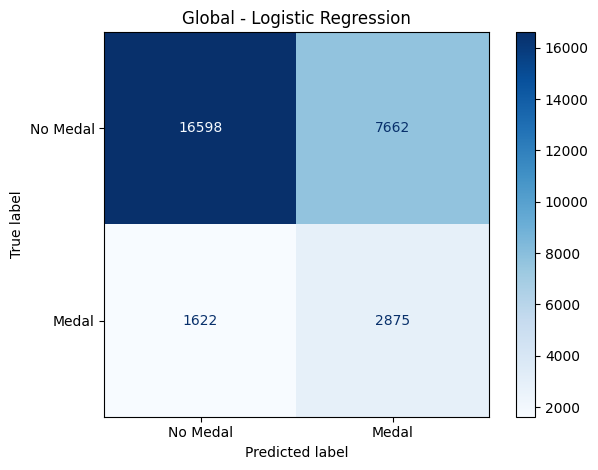

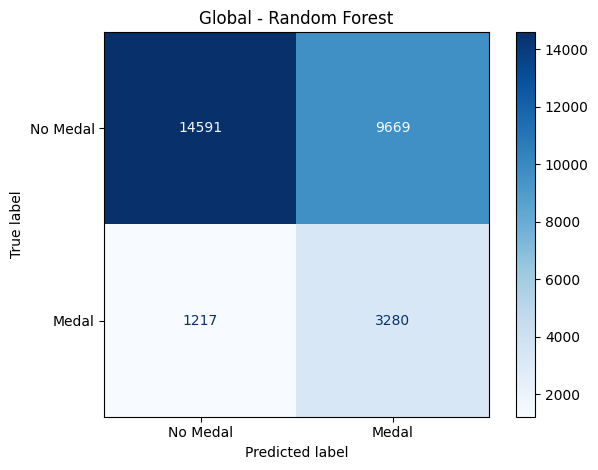

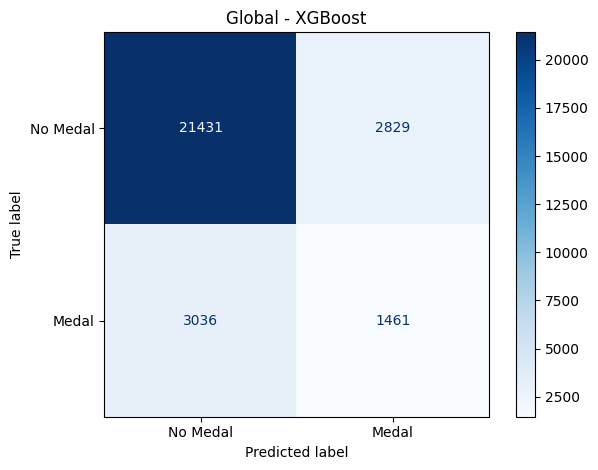

In [75]:
# Global models
plot_confusion_matrices(
    y_test,
    global_predictions,
    "Global"
)

#### Global - Logistic regression
- The model predicted 2,875 medal-winning records correctly.

- The model failed to predict 1,622 medal-winning records.

- There were 7,662 false positives out of 10,537 total predicted medals which indicates about 72.7% were incorrect predictions.

- The model performed better at predicting non-medal records comparitive to medal winning records.

#### Global - Random Forest Tree
- The model predicted 3,280 medal-winning records correctly.

- The model failed to predict 1,217 medal-winning records.

- There were 9,669 false positives out of 12,949 total predicted medals which indicates about 74.7% were incorrect predictions.

- The model performed better at predicting non-medal records comparitive to medal winning records.

#### Global - XGBoost
- The model predicted 1,461 medal-winning records correctly.

- The model failed to predict 3,036 medal-winning records.

- There were 2,829 false positives out of 4,290 total predicted medals which indicates about 65.9% were incorrect predictions.

- The model performed better at predicting non-medal records comparitive to medal winning records.

####Overview

- XGBoost total errors: $2,829 \text{ (FP)} + 3,036 \text{ (FN)} = 5,865$ total errors.   
- Logistic Regression total errors: $7,662 \text{ (FP)} + 1,622 \text{ (FN)} = 9,284$ total errors.   
- Random Forest total errors: $9,669 \text{ (FP)} + 1,217 \text{ (FN)} = 10,886$ total errors.   

**Overall the model that produced the most favorable results were XGBoost because XGBoost significantly cuts down false positive predictions while maintaining the lowest total mispredictions**

#### South African Models

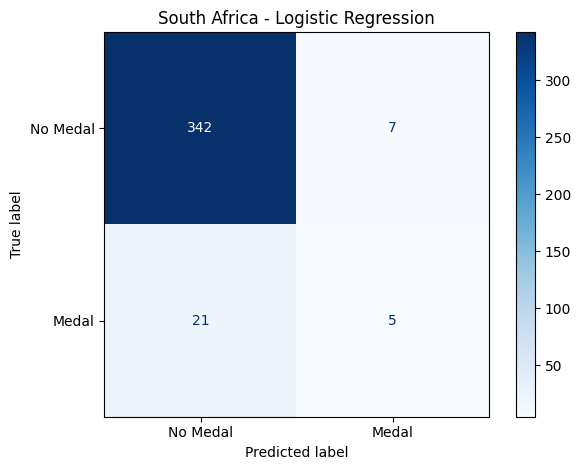

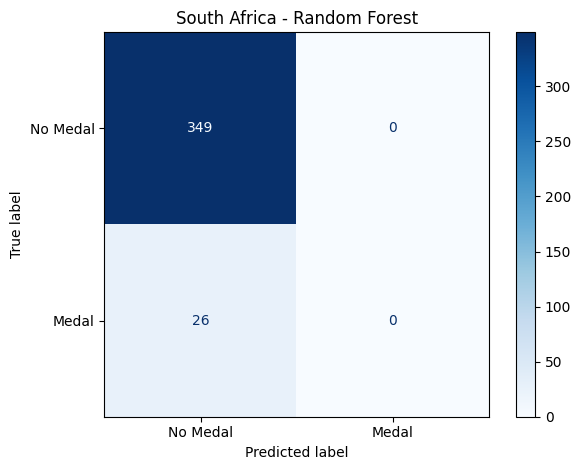

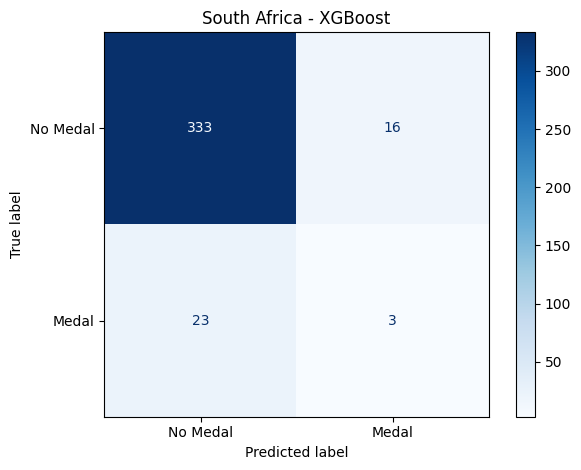

In [76]:
# South African models
plot_confusion_matrices(
    y_test_rsa,
    rsa_predictions,
    "South Africa"
)

#### South Africa - Logistic regression

- The model predicted 5 medal-winning records correctly.   
- The model failed to predict 21 medal-winning records.   
- There were 7 false positives out of 12 total predicted medals which indicates about 58.3% were incorrect predictions.   
- The model performed better at predicting non-medal records comparitive to medal winning records.

####South Africa - Random Forest Tree

- The model predicted 0 medal-winning records correctly.   
- The model failed to predict 26 medal-winning records.   
- There were 0 false positives out of 0 total predicted medals.   
- The model performed better at predicting non-medal records comparitive to medal winning records.

####South Africa - XGBoost
- The model predicted 3 medal-winning records correctly.   
- The model failed to predict 23 medal-winning records.   
- There were 16 false positives out of 19 total predicted medals which indicates about 84.2% were incorrect predictions.   
- The model performed better at predicting non-medal records comparitive to medal winning records

### Classification Report

In [77]:
def print_classification_reports(y_true, predictions, dataset_name):

    for name, results in predictions.items():

        print("\n" + "=" * 55)
        print(f"{dataset_name} - {name}")
        print("=" * 55)

        print(classification_report(
            y_true,
            results['predicted_class'],
            labels=[0, 1],
            target_names=['No Medal', 'Medal'],
            zero_division=0
        ))

#### **Global Models**

In [78]:
print_classification_reports(
    y_test,
    global_predictions,
    "Global"
)


Global - Logistic Regression
              precision    recall  f1-score   support

    No Medal       0.91      0.68      0.78     24260
       Medal       0.27      0.64      0.38      4497

    accuracy                           0.68     28757
   macro avg       0.59      0.66      0.58     28757
weighted avg       0.81      0.68      0.72     28757


Global - Random Forest
              precision    recall  f1-score   support

    No Medal       0.92      0.60      0.73     24260
       Medal       0.25      0.73      0.38      4497

    accuracy                           0.62     28757
   macro avg       0.59      0.67      0.55     28757
weighted avg       0.82      0.62      0.67     28757


Global - XGBoost
              precision    recall  f1-score   support

    No Medal       0.88      0.88      0.88     24260
       Medal       0.34      0.32      0.33      4497

    accuracy                           0.80     28757
   macro avg       0.61      0.60      0.61     28757
we

#### Global - Logistic regression
- Strengths: High sensitivity/recall for the minority class (63%). Out of all three models, Logistic Regression captures the largest total percentage of actual medalists ($2,833$ out of $4,497$).

- Weaknesses: Dismal precision for the minority class (27%). To catch those medalists, it casts an overly wide net and triggers an enormous volume of false positives (~$7,660$ non-medalists falsely predicted as medalists). Its overall accuracy (68%) performs significantly worse than the zero-rule baseline (84.4%).

- Verdict: High-recall, noise-heavy classifier. It behaves as if a decision threshold hyperparameter was aggressively shifted to favor sensitivity, or as if class weights were heavily penalized without tuning the cutoff boundary. Useful only if missing an actual medalist carries an extreme penalty relative to false alarms.

#### Global - Random Forest Tree
- Strengths: Improves overall balance between the two classes compared to Logistic Regression. Majority class specificity remains decent (83% recall on No Medal), raising overall accuracy to 77%.

- Weaknesses: Struggles with minority class identification. It achieves only 31% precision and 41% recall on Medal, resulting in a weak 0.35 F1-score. It misses 59% of all real medalists while still generating over 2.2 false alarms for every correct medal call.

- Verdict: Mediocre middle ground. Random Forest attempts to balance precision and recall natively, but without explicit class-weight adjustments or probability threshold tuning, it gets pulled toward predicting the majority class while losing its ability to reliably isolate minority instances.

#### Global - XGBoost

- Strengths: Highest overall accuracy (79%) and highest precision for the minority class (34%). It minimizes false positives more effectively than the other two models.

- Weaknesses: Lowest minority recall (33%) and lowest minority F1-score (0.33). XGBoost actively misses 67% of all true medalists in the dataset. Because gradient boosting optimizes for global log-loss, it heavily prioritizes getting the majority class right (88% precision/recall) at the direct expense of the minority class.

- Verdict: Conservative majority-skewed model. Despite having the highest overall accuracy, it is technically the worst performer for actually identifying medalists. It is heavily biased toward the majority class baseline.


#### **South African Models**

In [79]:
print_classification_reports(
    y_test_rsa,
    rsa_predictions,
    "South Africa"
)


South Africa - Logistic Regression
              precision    recall  f1-score   support

    No Medal       0.94      0.98      0.96       349
       Medal       0.42      0.19      0.26        26

    accuracy                           0.93       375
   macro avg       0.68      0.59      0.61       375
weighted avg       0.91      0.93      0.91       375


South Africa - Random Forest
              precision    recall  f1-score   support

    No Medal       0.93      1.00      0.96       349
       Medal       0.00      0.00      0.00        26

    accuracy                           0.93       375
   macro avg       0.47      0.50      0.48       375
weighted avg       0.87      0.93      0.90       375


South Africa - XGBoost
              precision    recall  f1-score   support

    No Medal       0.94      0.95      0.94       349
       Medal       0.16      0.12      0.13        26

    accuracy                           0.90       375
   macro avg       0.55      0.53     

#### South Africa - Logistic regression

- Strengths: Highest precision for the minority class (42%) and highest minority F1-score (0.26) among all South African models. When it predicts a medal, it is correct over 40% of the time.

- Weaknesses: Dismal minority recall (19%). It identifies only 5 out of the 26 actual South African medalists, missing 81% of them.

- Verdict: The best of a weak set, but still failing on recall. Linear decision boundaries extract slightly more signal from this small sample than trees, but without threshold adjustment or class weighting, it remains heavily anchored to the majority baseline.
####South Africa - Random Forest Tree

- Strengths: Near-perfect majority class recall (99%), resulting in a high headline accuracy of 93%.

- Weaknesses: Complete breakdown on minority detection. With a recall of 4%, it detects exactly 1 out of 26 actual medalists, generating an abysmal F1-score of 0.07.

- Verdict: Functionally useless as a medal detector. The algorithm defaulted to classifying almost every record as "No Medal" to optimize node purity and overall accuracy, rendering it a glorified majority-class estimator.

####South Africa - XGBoost

- Strengths: None relative to the other models.

- Weaknesses: Lowest precision (11%), lowest minority F1-score (0.06), and lowest overall accuracy (91%). Like Random Forest, it only catches 1 out of 26 actual medalists (4% recall), but it triggers 8 false alarms to get that single true positive.

- Verdict: Worst performer. Gradient boosting severely overfits the majority class on small, highly imbalanced datasets when hyperparameters (like max_depth, subsample, or scale_pos_weight) are left un-tuned

### Step 4: Calculate the evaluation metrics

In [80]:
def calculate_metrics(y_true, predictions, dataset_name):

    results_list = []

    for name, results in predictions.items():

        y_pred = results['predicted_class']
        y_prob = results['predicted_probability']

        results_list.append({

            'Dataset': dataset_name,
            'Model': name,

            'Accuracy': accuracy_score(y_true, y_pred),

            'Balanced Accuracy': balanced_accuracy_score(
                y_true, y_pred
            ),

            'Precision': precision_score(
                y_true, y_pred, zero_division=0
            ),

            'Recall': recall_score(
                y_true, y_pred, zero_division=0
            ),

            'F1-score': f1_score(
                y_true, y_pred, zero_division=0
            ),

            'ROC-AUC': roc_auc_score(y_true, y_prob),

            'PR-AUC': average_precision_score(y_true, y_prob)

        })

    return pd.DataFrame(results_list)

#### **Global models**

In [99]:
global_metrics = calculate_metrics(
    y_test,
    global_predictions,
    "Global"
)

print("GLOBAL MODEL RESULTS")
display(global_metrics)

GLOBAL MODEL RESULTS


,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Global,Logistic Regression,0.677157,0.661743,0.272848,0.639315,0.382466,0.721995,0.332865
1,Global,Random Forest,0.621449,0.665409,0.253301,0.729375,0.376017,0.718678,0.317966
2,Global,XGBoost,0.796050,0.604136,0.340559,0.324883,0.332537,0.732934,0.337626


GLOBAL MODEL RESULTS
Dataset	Model	Accuracy	Balanced Accuracy	Precision	Recall	F1-score	ROC-AUC	PR-AUC
0	Global	Logistic Regression	0.677157	0.661743	0.272848	0.639315	0.382466	0.721995	0.332865
1	Global	Random Forest	0.621449	0.665409	0.253301	0.729375	0.376017	0.718678	0.317966
2	Global	XGBoost	0.796050	0.604136	0.340559	0.324883	0.332537	0.732934	0.337626


#### **South African Models**

In [82]:
rsa_metrics = calculate_metrics(
    y_test_rsa,
    rsa_predictions,
    "South Africa"
)

print("SOUTH AFRICAN MODEL RESULTS")
display(rsa_metrics)

SOUTH AFRICAN MODEL RESULTS


,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,South Africa,Logistic Regression,0.925333,0.586125,0.416667,0.192308,0.263158,0.675446,0.190492
1,South Africa,Random Forest,0.930667,0.500000,0.000000,0.000000,0.000000,0.745757,0.151275
2,South Africa,XGBoost,0.896000,0.534770,0.157895,0.115385,0.133333,0.475975,0.122877


SOUTH AFRICAN MODEL RESULTS
Dataset	Model	Accuracy	Balanced Accuracy	Precision	Recall	F1-score	ROC-AUC	PR-AUC
0	South Africa	Logistic Regression	0.925333	0.586125	0.416667	0.192308	0.263158	0.675446	0.190492
1	South Africa	Random Forest	0.930667	0.500000	0.000000	0.000000	0.000000	0.745757	0.151275
2	South Africa	XGBoost	0.896000	0.534770	0.157895	0.115385	0.133333	0.475975	0.122877


Step 5: ROC-AUC graph

In [83]:
def plot_roc_curves(y_true, predictions, dataset_name):

    plt.figure(figsize=(9, 7))

    for name, results in predictions.items():

        y_prob = results['predicted_probability']

        fpr, tpr, thresholds = roc_curve(
            y_true,
            y_prob
        )

        auc_score = roc_auc_score(y_true, y_prob)

        plt.plot(
            fpr,
            tpr,
            label=f'{name} (AUC = {auc_score:.3f})'
        )

    # Random classification reference
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

    plt.title(f'{dataset_name} - ROC Curves')

    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

#### **Global Model**

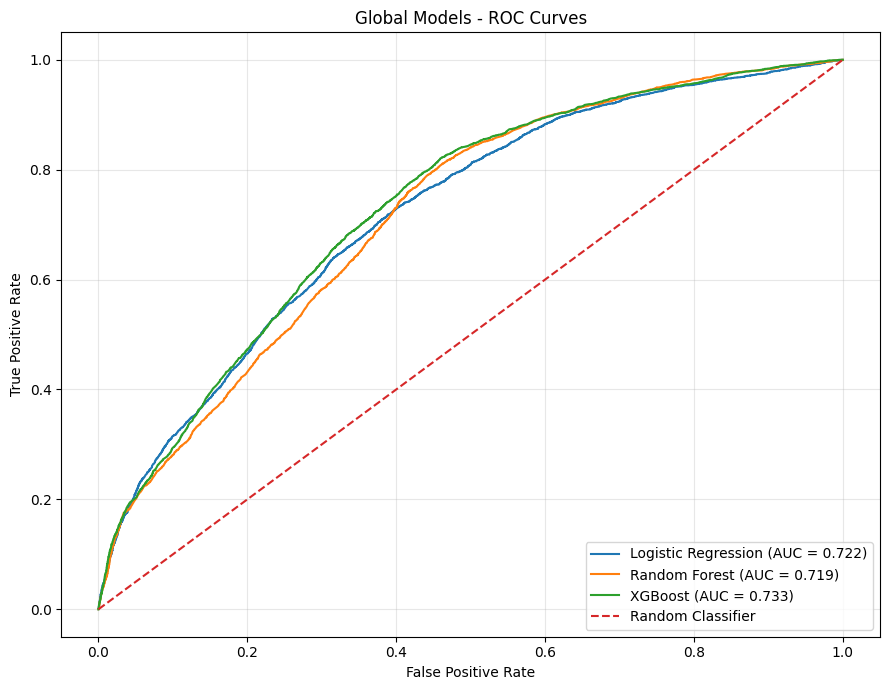

In [84]:
plot_roc_curves(
    y_test,
    global_predictions,
    "Global Models"
)

### Global model ROC-AUC Performance Evaluation

XGBoost has the highest ROC-AUC score of 0.733 (compared to 0.722 for Logistic Regression and 0.719 for Random Forest). XGBoost stays consistently above the other models across most False Positive Rates, making its curve the closest to the top-left corner overall.

All three global models (AUC: $0.719 - 0.733$) perform significantly better than the red dashed diagonal line of the Random Classifier ($\text{AUC} = 0.50$).   

The scores are very similar ($\text{AUC} = 0.719 \text{ to } 0.733$), showing consistent discrimination capability across all three algorithms on global data.   

#### **South African models**

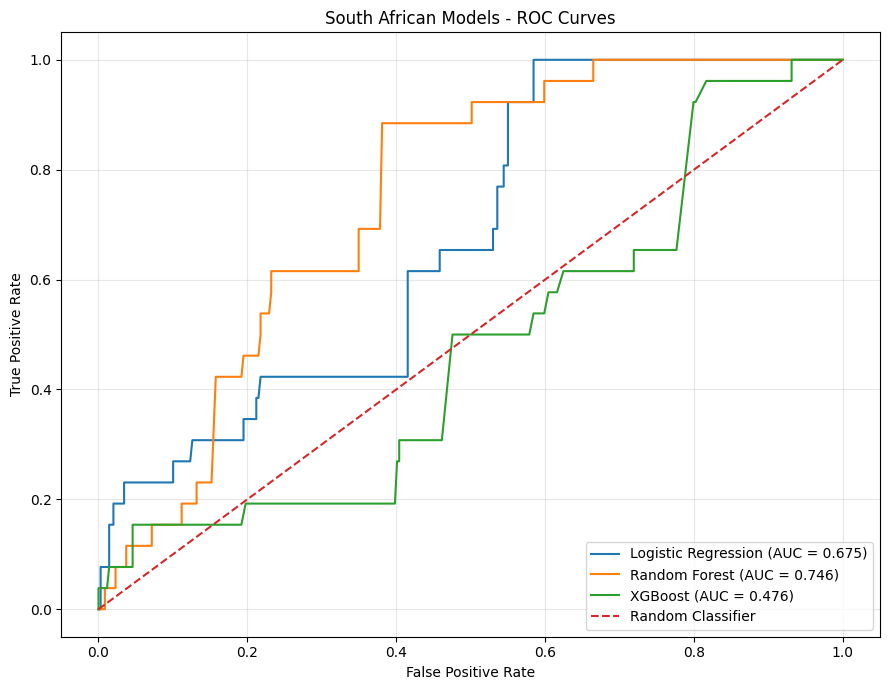

In [85]:
plot_roc_curves(
    y_test_rsa,
    rsa_predictions,
    "South African Models"
)

### Global model ROC-AUC Performance Evaluation

Random Forest has the highest ROC-AUC score of 0.746 (compared to 0.675 for Logistic Regression and 0.476 for XGBoost).

Random Forest dominates across most threshold levels and reaches the upper left area fastest.

Random Forest ($\text{AUC} = 0.746$) and Logistic Regression ($\text{AUC} = 0.675$) perform substantially better than random guessing whilst XGBoost ($\text{AUC} = 0.476$) performs worse than random chance.

The scores vary drastically. Random Forest (0.746) demonstrates noticeably better discrimination than Logistic Regression (0.675), while XGBoost (0.476) completely fails to discriminate.

### Global models Performance VS South African Medal Performance

On global data, XGBoost is the best-performing model ($\text{AUC} = 0.733$), whereas on South African data, XGBoost degrades severely into the worst performer ($\text{AUC} = 0.476$).

Random Forest improves from being the lowest global performer ($\text{AUC} = 0.719$) to becoming the best South African performer ($\text{AUC} = 0.746$).

Global ROC curves are smooth due to large sample sizes, while the South African ROC curves exhibit steep step-wise patterns due to smaller regional dataset sizes.


### Step 6: Precision-Recall curves

In [86]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_pr_curves(y_true, predictions, dataset_name):

    plt.figure(figsize=(9, 7))

    for name, results in predictions.items():

        y_prob = results['predicted_probability']

        precision, recall, thresholds = precision_recall_curve(
            y_true,
            y_prob
        )

        pr_auc = average_precision_score(
            y_true,
            y_prob
        )

        plt.plot(
            recall,
            precision,
            label=f'{name} (AP = {pr_auc:.3f})'
        )

    # Baseline: positive-class prevalence
    baseline = y_true.mean()

    plt.axhline(
        y=baseline,
        linestyle='--',
        label=f'Baseline = {baseline:.3f}'
    )

    plt.xlabel('Recall')
    plt.ylabel('Precision')

    plt.title(f'{dataset_name} - Precision-Recall Curves')

    plt.legend(loc='best')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

#### **Global Models**

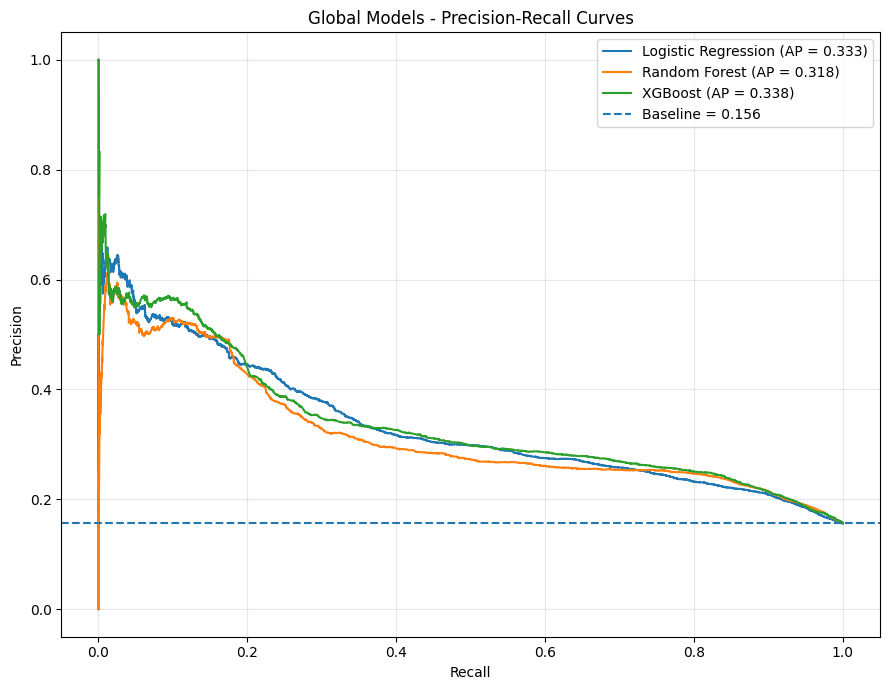

In [87]:
plot_pr_curves(
    y_test,
    global_predictions,
    "Global Models"
)

1. Which model achieves the best precision at higher recall levels?

    At moderate-to-high recall ($0.40$ to $0.80$): XGBoost and Logistic Regression perform very closely, but XGBoost slightly maintains higher precision over most of this range, overall achieving the highest Average Precision ($\text{AP} = 0.338$) compared to Logistic Regression ($\text{AP} = 0.333$) and Random Forest ($\text{AP} = 0.318$).  
    
     At very high recall ($0.80$ to $1.00$): XGBoost (green line) and Random Forest (orange line) track together and achieve slightly better precision than Logistic Regression, before all three converge at the baseline precision of $0.156$ when recall reaches $1.00$.   

2. Does precision drop substantially as recall increases?
    
    Yes. Across all three models, precision drops continuously and substantially as recall increases:   
     
     - At low recall ($\approx 0.05 - 0.15$), precision ranges between 0.50 and 0.65.  
     
      - At moderate recall ($\approx 0.50$), precision drops to approximately 0.30.   
      
      - At high recall ($\ge 0.80$), precision falls toward 0.20 – 0.25, eventually dropping to the random baseline of 0.156 at maximum recall ($1.00$).

  
  All three curves sit consistently above the global baseline positive-class prevalence of 0.156 across virtually all recall thresholds


#### South African Models

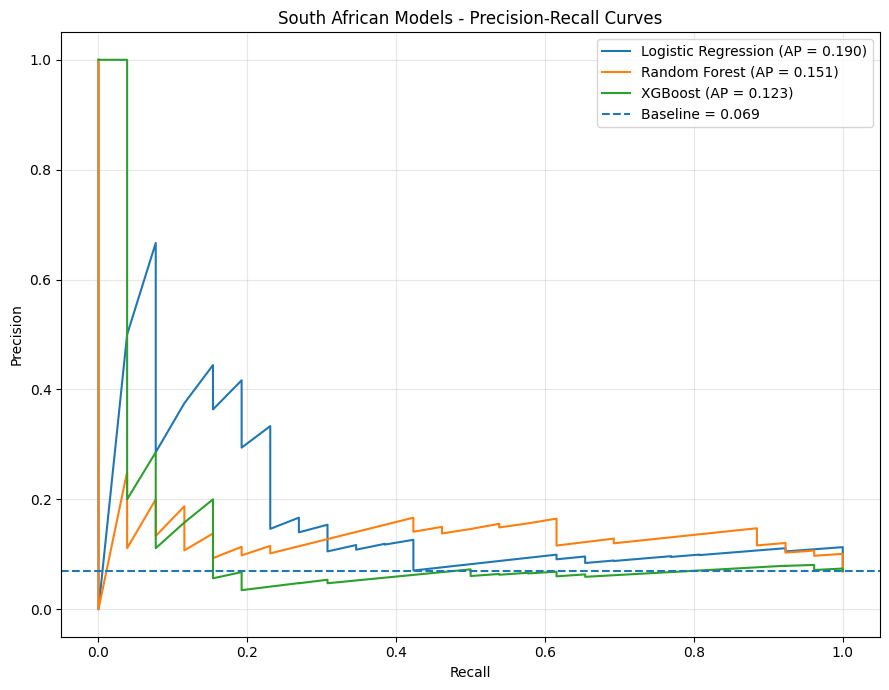

In [88]:
plot_pr_curves(
    y_test_rsa,
    rsa_predictions,
    "South African Models"
)

1. Which model achieves the best precision at higher recall levels?

    - At moderate-to-high recall ($0.30$ to $0.90$): Random Forest (orange line) achieves the best precision, staying consistently above Logistic Regression and XGBoost across this range.  
    
     - At very high recall ($0.90$ to $1.00$): Logistic Regression (blue line) slightly overtakes Random Forest, maintaining the highest precision before all models converge at the baseline precision of $0.069$ at maximum recall ($1.00$).   
     
     - Overall Average Precision: Logistic Regression achieves the highest overall Average Precision score ($\text{AP} = 0.190$), followed by Random Forest ($\text{AP} = 0.151$) and XGBoost ($\text{AP} = 0.123$).   

2. Does precision drop substantially as recall increases?Yes. Precision drops steeply as recall increases across all three models:

    - At very low recall ($\le 0.08$), models achieve peak precision (XGBoost reaches $1.00$, and Logistic Regression spikes to $\sim 0.67$).  
    -  By moderate recall ($\approx 0.25 - 0.40$), precision drops dramatically to between 0.10 and 0.15.   
    - At high recall ($\ge 0.50$), precision remains low (between 0.05 and 0.15), ultimately converging at the random baseline of 0.069 when recall reaches $1.00$.   

3. Are the South African models performing better than their baseline positive-class prevalence?

    - Yes, for the most part.The baseline positive-class prevalence for the South African dataset is 0.069 (dashed blue line).  
     
    - Logistic Regression and Random Forest operate consistently above the baseline across nearly the entire recall spectrum ($0.05$ to $1.00$).
    
     - XGBoost performs above the baseline at very low recall ($\le 0.15$), but dips slightly below the baseline between recall levels of $0.20$ and $0.70$ before returning to the baseline near maximum recall.

### Classification threshold analysis

In [89]:
from sklearn.metrics import precision_score, recall_score, f1_score

def threshold_analysis(y_true, probabilities):

    results = []

    thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        results.append({

            'Threshold': threshold,

            'Precision': precision_score(
                y_true, predictions, zero_division=0
            ),

            'Recall': recall_score(
                y_true, predictions, zero_division=0
            ),

            'F1-score': f1_score(
                y_true, predictions, zero_division=0
            )

        })

    return pd.DataFrame(results)

In [90]:
rsa_lr_thresholds = threshold_analysis(
    y_test_rsa,
    rsa_predictions['Logistic Regression']['predicted_probability']
)

display(rsa_lr_thresholds)

,Threshold,Precision,Recall,F1-score
0,0.2,0.114286,0.307692,0.166667
1,0.3,0.162791,0.269231,0.202899
2,0.4,0.260870,0.230769,0.244898
3,0.5,0.416667,0.192308,0.263158
4,0.6,0.285714,0.076923,0.121212
5,0.7,0.666667,0.076923,0.137931
6,0.8,0.000000,0.000000,0.000000


Threshold	Precision	Recall	F1-score
0	0.2	0.114286	0.307692	0.166667
1	0.3	0.162791	0.269231	0.202899
2	0.4	0.260870	0.230769	0.244898
3	0.5	0.416667	0.192308	0.263158
4	0.6	0.285714	0.076923	0.121212
5	0.7	0.666667	0.076923	0.137931
6	0.8	0.000000	0.000000	0.000000

## Comparison evaluation for the three Global models

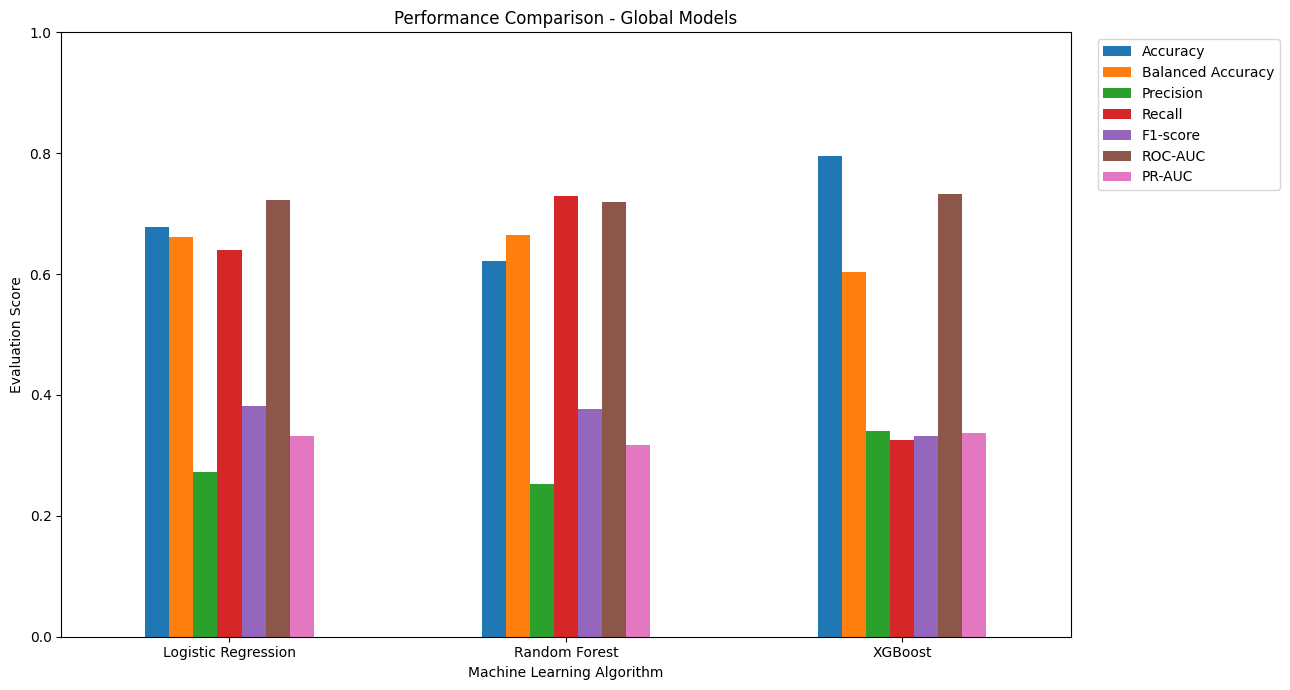

In [91]:
global_comparison = global_metrics.set_index('Model')[
    ['Accuracy', 'Balanced Accuracy',
     'Precision', 'Recall', 'F1-score',
     'ROC-AUC', 'PR-AUC']
]

global_comparison.plot(
    kind='bar',
    figsize=(13, 7)
)

plt.title('Performance Comparison - Global Models')
plt.xlabel('Machine Learning Algorithm')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

1. Which algorithm achieved the highest accuracy?

    - XGBoost achieved the highest accuracy (blue bar), reaching approximately 0.80 ($\sim 80\%$).   

2. Which algorithm achieved the highest precision for medal-winning records?

    - XGBoost achieved the highest precision (green bar), reaching approximately 0.34 ($\sim 34\%$).  

3. Which algorithm achieved the highest recall for medal-winning records?

     - Random Forest achieved the highest recall (red bar), reaching approximately 0.73 ($\sim 73\%$).   

4. Which algorithm achieved the highest F1-score?

    - Logistic Regression achieved the highest F1-score (purple bar), slightly outperforming Random Forest at approximately 0.38.   

5. Which algorithm achieved the highest ROC-AUC and PR-AUC?

   - Highest ROC-AUC (brown bar): XGBoost achieved the highest ROC-AUC score at 0.733.

   - Highest PR-AUC (pink bar): XGBoost achieved the highest PR-AUC score at approximately 0.34.   

6. Does the same model perform best across all evaluation metrics?

   - No. Different models excel at different metrics:   XGBoost dominates in Accuracy, Precision, ROC-AUC, and PR-AUC.   Random Forest dominates in Recall.   Logistic Regression achieves the highest F1-score and Balanced Accuracy.   

7. Does one model demonstrate a better balance between identifying medal-winning records and avoiding false positives?

Yes. Logistic Regression demonstrates the most balanced overall performance:
   -  It achieves the highest F1-score ($\approx 0.38$).   
  - It maintains the highest Balanced Accuracy ($\approx 0.66$).   
  - It balances strong Recall ($\approx 0.64$) with decent Precision without collapsing on minority-class detection like XGBoost or generating excessive false positives like Random Forest.   

## Comparison evaluation for the three South African models

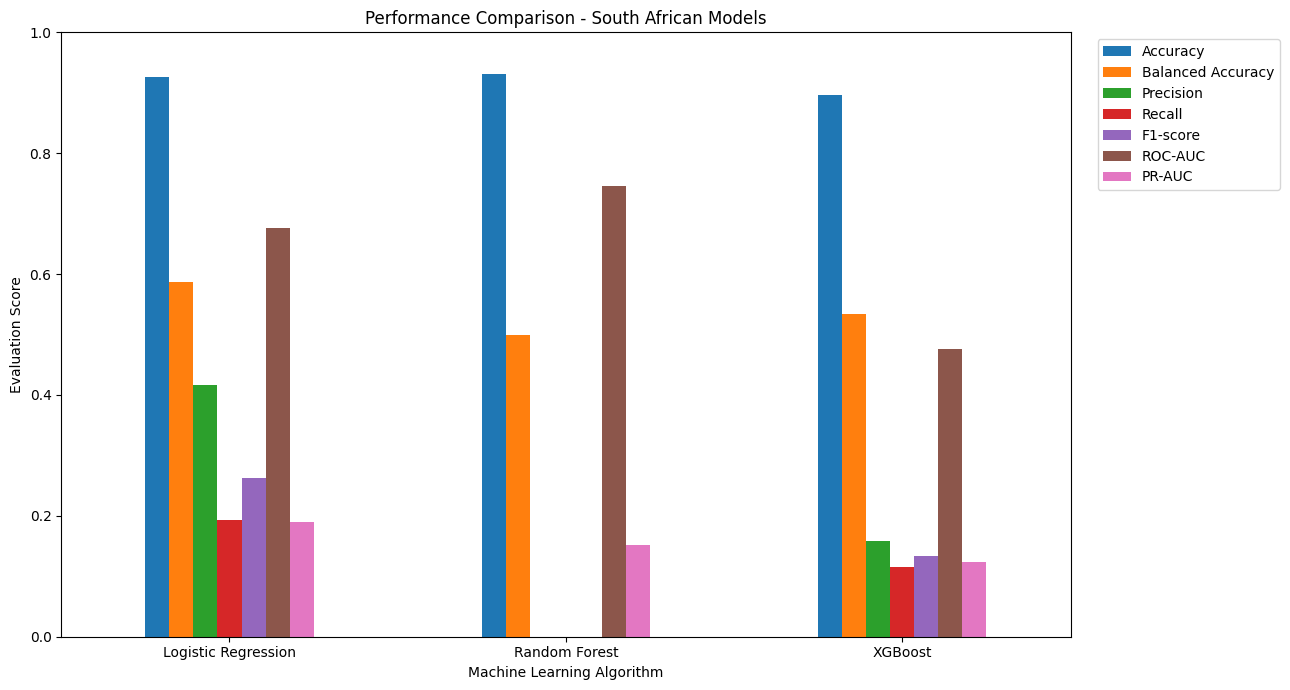

In [92]:
rsa_comparison = rsa_metrics.set_index('Model')[
    ['Accuracy', 'Balanced Accuracy',
     'Precision', 'Recall', 'F1-score',
     'ROC-AUC', 'PR-AUC']
]

rsa_comparison.plot(
    kind='bar',
    figsize=(13, 7)
)

plt.title('Performance Comparison - South African Models')
plt.xlabel('Machine Learning Algorithm')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

1. Which algorithm achieved the highest accuracy?

   - Random Forest achieved the highest accuracy (blue bar), reaching approximately 0.93 ($\sim 93\%$), closely followed by Logistic Regression ($\sim 92.5\%$) and XGBoost ($\sim 89.5\%$).   

2. Which algorithm achieved the highest precision for medal-winning records?    

     - Logistic Regression achieved the highest precision (green bar), reaching approximately 0.42 ($\sim 42\%$). XGBoost reached approximately 0.16 ($\sim 16\%$), while Random Forest achieved a precision of 0.00 ($\sim 0\%$) as it failed to predict any true positive medal winners.   

3. Which algorithm achieved the highest recall for medal-winning records?
    - Logistic Regression achieved the highest recall (red bar), reaching approximately 0.19 ($\sim 19\%$). XGBoost achieved a recall of approximately 0.12 ($\sim 12\%$), while Random Forest achieved 0.00 ($\sim 0\%$).   

4. Which algorithm achieved the highest F1-score?

   - Logistic Regression achieved the highest F1-score (purple bar) at approximately 0.26. XGBoost achieved approximately 0.13, and Random Forest registered 0.00.   

5. Which algorithm achieved the highest ROC-AUC and PR-AUC?

    - Highest ROC-AUC (brown bar): Random Forest achieved the highest ROC-AUC score at 0.746, followed by Logistic Regression at 0.675, and XGBoost at 0.476.   
    - Highest PR-AUC (pink bar): Logistic Regression achieved the highest PR-AUC score at approximately 0.19, followed by Random Forest ($\sim 0.15$) and XGBoost ($\sim 0.12$).   

6. Does the same model perform best across all evaluation metrics?

    - No. Random Forest has the highest overall Accuracy ($\sim 0.93$) and ROC-AUC ($0.746$), but completely fails on class-level metrics for medal winners (Precision, Recall, and F1-score are all $0.00$).  

    - Logistic Regression dominates in Balanced Accuracy, Precision, Recall, F1-score, and PR-AUC.   

7. Does one model demonstrate a better balance between identifying medal-winning records and avoiding false positives?

- Yes. Logistic Regression is clearly the most balanced model for the South African dataset:

  -   It achieves the highest F1-score ($\approx 0.26$).  
  
  -  It maintains the highest Balanced Accuracy ($\approx 0.59$).

  - It is the only model capable of producing meaningful positive predictions, outperforming XGBoost (which has high false positives relative to true positives) and Random Forest (which simply predicts "No Medal" for every record).  

## Comparison of the Global models VS South African models

This evaluation should establish whether training on the entire Olympic population provides an advantage when predicting South African medal-winning performances.

We must first ensure that the records that are being tested on in both approaches must be evaluated on exactly the same South African test records.

The evaluation should not compare:
- Global models evaluated on all countries.
- South African models evaluated only on South Africa.

Both the Global models and South African models should be tested on the same data

#### Step 1: Extract the South African records from the global test set

In [93]:
# Find the positions of the RSA test records in the global test set
rsa_test_positions = X_test.index.get_indexer(
    X_test_rsa.index
)

# Check that all RSA test records were found
if (rsa_test_positions < 0).any():
    raise ValueError(
        "Some RSA test records were not found in the global test set."
    )

# Confirm target alignment
y_test_global_rsa = y_test.loc[X_test_rsa.index]

assert y_test_global_rsa.equals(y_test_rsa)

print("Number of shared RSA test records:",
      len(rsa_test_positions))

Number of shared RSA test records: 375


#### Step 2: Generate global-model predictions for South Africa

In [94]:
global_rsa_predictions = {}

# Logistic Regression
global_rsa_predictions['Logistic Regression'] = {
    'predicted_class': lr_model.predict(
        X_test_lr[rsa_test_positions]
    ),
    'predicted_probability': lr_model.predict_proba(
        X_test_lr[rsa_test_positions]
    )[:, 1]
}

# Random Forest
global_rsa_predictions['Random Forest'] = {
    'predicted_class': rf_model.predict(
        X_test_tree[rsa_test_positions]
    ),
    'predicted_probability': rf_model.predict_proba(
        X_test_tree[rsa_test_positions]
    )[:, 1]
}

# XGBoost
global_rsa_predictions['XGBoost'] = {
    'predicted_class': xgb_model.predict(
        X_test_tree[rsa_test_positions]
    ),
    'predicted_probability': xgb_model.predict_proba(
        X_test_tree[rsa_test_positions]
    )[:, 1]
}

####Step 3: Evaluate all six models on South African records

In [95]:
global_vs_rsa_predictions = {}

for name, results in global_rsa_predictions.items():

    global_vs_rsa_predictions[
        f'Global {name}'
    ] = results

for name, results in rsa_predictions.items():

    global_vs_rsa_predictions[
        f'RSA {name}'
    ] = results


global_vs_rsa_metrics = calculate_metrics(
    y_test_rsa,
    global_vs_rsa_predictions,
    "South African Test Records"
)

display(
    global_vs_rsa_metrics.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)

,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
3,South African Test Records,RSA Logistic Regression,0.9253,0.5861,0.4167,0.1923,0.2632,0.6754,0.1905
1,South African Test Records,Global Random Forest,0.4693,0.5903,0.0900,0.7308,0.1603,0.4998,0.0738
5,South African Test Records,RSA XGBoost,0.8960,0.5348,0.1579,0.1154,0.1333,0.4760,0.1229
2,South African Test Records,Global XGBoost,0.7013,0.5014,0.0700,0.2692,0.1111,0.5743,0.0834
0,South African Test Records,Global Logistic Regression,0.5147,0.2943,0.0063,0.0385,0.0109,0.4005,0.0585
4,South African Test Records,RSA Random Forest,0.9307,0.5000,0.0000,0.0000,0.0000,0.7458,0.1513


Dataset	Model	Accuracy	Balanced Accuracy	Precision	Recall	F1-score	ROC-AUC	PR-AUC
3	South African Test Records	RSA Logistic Regression	0.9253	0.5861	0.4167	0.1923	0.2632	0.6754	0.1905
1	South African Test Records	Global Random Forest	0.4693	0.5903	0.0900	0.7308	0.1603	0.4998	0.0738
5	South African Test Records	RSA XGBoost	0.8960	0.5348	0.1579	0.1154	0.1333	0.4760	0.1229
2	South African Test Records	Global XGBoost	0.7013	0.5014	0.0700	0.2692	0.1111	0.5743	0.0834
0	South African Test Records	Global Logistic Regression	0.5147	0.2943	0.0063	0.0385	0.0109	0.4005	0.0585
4	South African Test Records	RSA Random Forest	0.9307	0.5000	0.0000	0.0000	0.0000	0.7458	0.1513


#### Step 4: Visualise the comparison

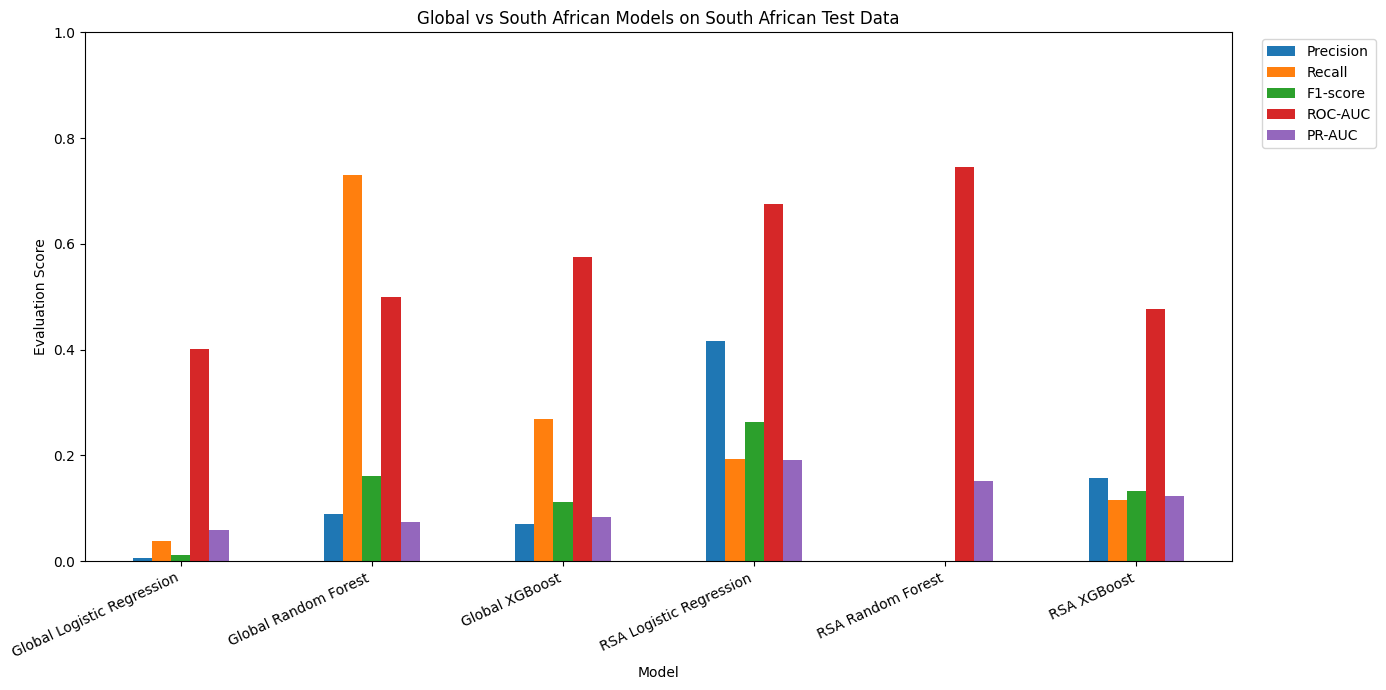

In [96]:
comparison_plot = global_vs_rsa_metrics.set_index('Model')[
    ['Precision', 'Recall', 'F1-score', 'ROC-AUC', 'PR-AUC']
]

comparison_plot.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Global vs South African Models on South African Test Data')
plt.xlabel('Model')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)

plt.xticks(rotation=25, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

1. Do the global models achieve better predictive performance on South African records than the South African-specific models?

    It depends on the metric used to define performance:

 -   For Recall: Global models perform significantly better, with Global Random Forest reaching the highest overall recall ($\approx 0.73$).

  - For Precision, F1-score, and PR-AUC: South African-specific models (specifically RSA Logistic Regression) achieve superior results.

  - For ROC-AUC: RSA Random Forest achieves the single highest ROC-AUC ($\approx 0.746$), though Global XGBoost and RSA Logistic Regression also demonstrate competitive discrimination ($\approx 0.58$ and $\approx 0.68$, respectively).

  2. Does the global model identify a greater proportion of actual South African medal-winning records?

  Yes. Global models identify a much higher proportion of actual medal winners (Recall):  
   
  - Global Random Forest achieves a recall of approximately 0.73 ($\sim 73\%$).   

   - Global XGBoost achieves a recall of approximately 0.27 ($\sim 27\%$)

   - In contrast, the highest recall among South African-specific models is RSA Logistic Regression at only 0.19 ($\sim 19\%$), while RSA Random Forest fails entirely to recall any medal-winning records ($0.00$).

3. Do South African-specific models achieve better precision despite potentially lower recall?

 Yes. South African-specific models yield far more reliable positive predictions:   

  - RSA Logistic Regression achieves the highest precision across all evaluated models at approximately 0.42 ($\sim 42\%$).   
  
  - RSA XGBoost achieves a precision of approximately 0.16 ($\sim 16\%$).   
  
  - By contrast, precision for global models on South African test data remains low: Global Random Forest is under 0.10 ($\sim 9\%$), Global XGBoost is around 0.07 ($\sim 7\%$), and Global Logistic Regression is near 0.01 ($\sim 1\%$).   

5. Does training on the larger global dataset provide a predictive advantage?

    Yes, primarily for sensitivity/recall, but at the cost of precision:   

 - The larger, more diverse global dataset helps the models learn broader patterns associated with winning medals, allowing models like Global Random Forest to flag a much larger majority of true medal winners.  

 - However, because global patterns do not fully align with local South African baseline rates, global models suffer from high false-positive rates when applied locally, leading to poor precision.

 6. Could differences in performance be explained by the size of the training datasets?

    Yes, dataset size and class imbalance significantly influence the results:

  - Global models benefit from a much larger sample size, which prevents complete collapse on minority class detection and allows high recall.   
  
  - RSA-specific models are trained on a much smaller dataset with extremely few positive medal instances. As a result, conservative tree models like RSA Random Forest default to predicting "No Medal" for all instances (yielding $0.00$ for precision, recall, and F1-score), whereas RSA Logistic Regression manages to fit a more conservative boundary that sacrifices recall to maximize precision.   
  
  7. Do the results suggest that the global population provides useful information for predicting South African performances?
  
  Yes. The strong recall of the global models (e.g., Global Random Forest detecting $\sim 73\%$ of true South African medal winners) demonstrates that global performance trends contain valuable signal for identifying potential South African medalists. However, transferring a global model directly without local recalibration introduces high false positive rates. A hybrid approach—pre-training on global data and fine-tuning or threshold-adjusting on South African data—would likely yield the best balance.





In [98]:
from sklearn.metrics import classification_report
import numpy as np

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

# Extracting the correct global Logistic Regression probabilities and true targets
y_prob_global_lr = global_predictions['Logistic Regression']['predicted_probability']
y_test_global = y_test

for threshold in thresholds:

    y_pred = (
        y_prob_global_lr >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print(classification_report(
        y_test_global,
        y_pred,
        target_names=["No Medal", "Medal"],
        zero_division=0
    ))


Threshold: 0.2
              precision    recall  f1-score   support

    No Medal       0.96      0.23      0.37     24260
       Medal       0.19      0.95      0.31      4497

    accuracy                           0.34     28757
   macro avg       0.57      0.59      0.34     28757
weighted avg       0.84      0.34      0.36     28757


Threshold: 0.3
              precision    recall  f1-score   support

    No Medal       0.94      0.43      0.59     24260
       Medal       0.22      0.86      0.35      4497

    accuracy                           0.50     28757
   macro avg       0.58      0.65      0.47     28757
weighted avg       0.83      0.50      0.55     28757


Threshold: 0.4
              precision    recall  f1-score   support

    No Medal       0.93      0.58      0.71     24260
       Medal       0.25      0.75      0.37      4497

    accuracy                           0.60     28757
   macro avg       0.59      0.66      0.54     28757
weighted avg       0.82   

## Feature Importance Rankings

In [105]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

def calculate_feature_importance(preprocessor, model, X_eval, y_eval, model_name):

    # Combine the already-fitted preprocessor and model
    fitted_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Calculate permutation importance
    results = permutation_importance(
        fitted_pipeline,
        X_eval,
        y_eval,
        scoring='average_precision',
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        'Feature': X_eval.columns,
        'Importance': results.importances_mean,
        'Std': results.importances_std,
        'Model': model_name
    })

    return importance_df.sort_values(
        by='Importance',
        ascending=False
    )

RSA Logistic Regression model

In [106]:
rsa_lr_importance = calculate_feature_importance(
    preprocessor_rsa_lr,
    lr_rsa_weighted,
    X_test_rsa_imputed,
    y_test_rsa,
    'RSA Logistic Regression'
)

display(rsa_lr_importance.head(10))

,Feature,Importance,Std,Model
6,event,0.087555,0.015854,RSA Logistic Regression
2,previous_olympic_participation,0.040569,0.026269,RSA Logistic Regression
5,sport,0.036596,0.040441,RSA Logistic Regression
0,age,0.012726,0.018307,RSA Logistic Regression
3,previous_medal_achievement,0.007541,0.010335,RSA Logistic Regression
4,sex,0.004604,0.003575,RSA Logistic Regression
1,year,0.003002,0.001422,RSA Logistic Regression
7,isTeamSport,-0.011713,0.006655,RSA Logistic Regression


RSA Random Forest model

In [108]:
rsa_rf_importance = calculate_feature_importance(
    preprocessor_rsa_tree,
    rf_model_rsa,
    X_test_rsa_imputed,
    y_test_rsa,
    'RSA Random Forest Model'
)

display(rsa_rf_importance.head(10))

,Feature,Importance,Std,Model
6,event,0.038827,0.016582,RSA Random Forest Model
5,sport,0.031000,0.024101,RSA Random Forest Model
7,isTeamSport,0.017523,0.005358,RSA Random Forest Model
4,sex,0.015256,0.004903,RSA Random Forest Model
2,previous_olympic_participation,0.006419,0.017665,RSA Random Forest Model
3,previous_medal_achievement,0.003506,0.001785,RSA Random Forest Model
1,year,0.000000,0.000000,RSA Random Forest Model
0,age,-0.024371,0.033221,RSA Random Forest Model


RSA XGBoost model

In [110]:
rsa_xgb_importance = calculate_feature_importance(
    preprocessor_rsa_tree,
    xgb_model_rsa,
    X_test_rsa_imputed,
    y_test_rsa,
    'RSA XGBoost model'
)

display(rsa_xgb_importance.head(10))

,Feature,Importance,Std,Model
5,sport,0.044158,0.008806,RSA XGBoost model
2,previous_olympic_participation,0.044075,0.014952,RSA XGBoost model
0,age,0.028027,0.022993,RSA XGBoost model
7,isTeamSport,0.011280,0.013400,RSA XGBoost model
4,sex,0.007962,0.008653,RSA XGBoost model
6,event,0.006893,0.014270,RSA XGBoost model
3,previous_medal_achievement,0.000000,0.000000,RSA XGBoost model
1,year,0.000000,0.000000,RSA XGBoost model


Global models

In [112]:
# Create a copy of the RSA evaluation dataset and add the missing 'is_host_country' column
X_test_rsa_imputed_global_aligned = X_test_rsa_imputed.copy()
X_test_rsa_imputed_global_aligned['is_host_country'] = 0

# Ensure the columns match the exact order of the global training columns
X_test_rsa_imputed_global_aligned = X_test_rsa_imputed_global_aligned[X_train_imputed.columns]

## Logistic regression
global_lr_importance = calculate_feature_importance(
    preprocessor_lr,
    lr_model,
    X_test_rsa_imputed_global_aligned,
    y_test_rsa,
    'Global Logistic Regression'
)

display(global_lr_importance.head(10))

global_rf_importance = calculate_feature_importance(
    preprocessor_tree,
    rf_model,
    X_test_rsa_imputed_global_aligned,
    y_test_rsa,
    'Global Random Forest Model'
)

display(global_rf_importance.head(10))

global_xgb_importance = calculate_feature_importance(
    preprocessor_tree,
    xgb_model,
    X_test_rsa_imputed_global_aligned,
    y_test_rsa,
    'Global XGBoost model'
)

display(global_xgb_importance.head(10))

comparison_df = pd.concat(
    [global_lr_importance, rsa_lr_importance, global_rf_importance, rsa_rf_importance, global_xgb_importance, rsa_xgb_importance],
    ignore_index=True
)

,Feature,Importance,Std,Model
0,age,0.002103,0.000787,Global Logistic Regression
1,year,0.001702,0.000238,Global Logistic Regression
5,sex,0.001276,0.000280,Global Logistic Regression
3,previous_olympic_participation,0.001087,0.000598,Global Logistic Regression
2,is_host_country,0.000000,0.000000,Global Logistic Regression
6,sport,-0.001496,0.002285,Global Logistic Regression
4,previous_medal_achievement,-0.002693,0.010969,Global Logistic Regression
8,isTeamSport,-0.006317,0.010545,Global Logistic Regression
7,event,-0.010459,0.005343,Global Logistic Regression


,Feature,Importance,Std,Model
0,age,0.006571,0.001825,Global Random Forest Model
7,event,0.003840,0.001642,Global Random Forest Model
3,previous_olympic_participation,0.003058,0.000962,Global Random Forest Model
5,sex,0.001009,0.001251,Global Random Forest Model
1,year,0.000000,0.000000,Global Random Forest Model
2,is_host_country,0.000000,0.000000,Global Random Forest Model
6,sport,-0.002734,0.005531,Global Random Forest Model
4,previous_medal_achievement,-0.004031,0.011282,Global Random Forest Model
8,isTeamSport,-0.017164,0.016999,Global Random Forest Model


,Feature,Importance,Std,Model
0,age,0.011350,0.003612,Global XGBoost model
3,previous_olympic_participation,0.003539,0.003314,Global XGBoost model
1,year,0.000000,0.000000,Global XGBoost model
2,is_host_country,0.000000,0.000000,Global XGBoost model
5,sex,-0.001503,0.001046,Global XGBoost model
7,event,-0.003048,0.002064,Global XGBoost model
4,previous_medal_achievement,-0.006688,0.021770,Global XGBoost model
6,sport,-0.016733,0.009584,Global XGBoost model
8,isTeamSport,-0.026822,0.022046,Global XGBoost model


### Bar Graph comparing the importance of features between different models.

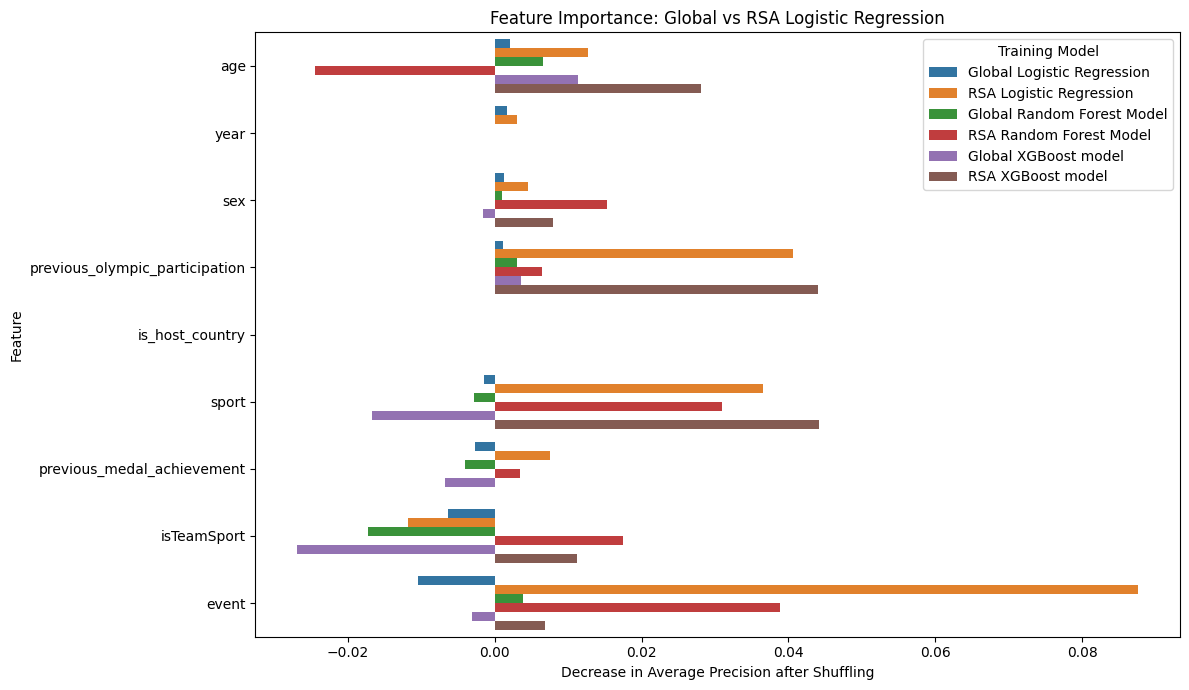

In [113]:
top_features = (
    comparison_df.groupby('Feature')['Importance']
    .mean()
    .nlargest(10)
    .index
)

plot_df = comparison_df[
    comparison_df['Feature'].isin(top_features)
]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_df,
    x='Importance',
    y='Feature',
    hue='Model'
)

plt.title('Feature Importance: Global vs RSA Logistic Regression')
plt.xlabel('Decrease in Average Precision after Shuffling')
plt.ylabel('Feature')
plt.legend(title='Training Model')
plt.tight_layout()
plt.show()

#### Feature Importance Analysis: Global vs. South Africa Models

1. Core Feature Contributions to Medal Prediction
Across the evaluated models, feature influence varies depending on whether the algorithm is trained on the global dataset or localized South African data:

 -   Event Specificity (event): Serves as the single most dominant predictor for RSA Logistic Regression (importance score of 0.087) and plays a strong role in RSA Random Forest (0.039). However, for global models (such as Global Logistic Regression and Global XGBoost), shuffling the event feature results in a negative change in average precision, indicating minimal direct reliance or noise sensitivity at the global scale.

 -   Previous Olympic Experience (previous_olympic_participation): Exhibits high positive importance across localized South Africa models—specifically RSA XGBoost (0.044) and RSA Logistic Regression (0.041). It also maintains positive, albeit smaller, contribution values across all global models.

 -   Specific Discipline (sport): Demonstrates strong predictive importance in RSA XGBoost (~.044), RSA Logistic Regression (0.037), and RSA Random Forest (0.031). In contrast, it yields negative importance values in Global XGBoost (-0.017) and Global Random Forest (-0.003).  

 - Athlete Age (age): Acts as a key driver for RSA XGBoost (0.028) and Global XGBoost (0.011), as well as RSA Logistic Regression (0.013). Conversely, it shows a strong negative importance in RSA Random Forest (-0.024).  

 - Team Sport Flag (isTeamSport): Exhibits positive importance for RSA Random Forest (0.018) and RSA XGBoost (0.011). For global models (Global XGBoost, Global Random Forest, and Global Logistic Regression) as well as RSA Logistic Regression, shuffling isTeamSport results in a drop in model precision (negative importance down to -0.027).  

Key Comparative Insights for Your Discussion

Context-Specific Feature Reliance:

 - South Africa-trained models depend heavily on localized categorical context—specifically event and sport. In a localized dataset with a smaller cohort of elite athletes, specific event categories and sport types carry strong baseline signals regarding where South Africa historically fields competitive contenders (e.g., Swimming, Athletics, Rowing). Global models, operating across thousands of diverse events, cannot leverage these localized priors as strongly.   

Impact of Prior Olympic Exposure:

  - previous_olympic_participation is considerably more impactful in South African models than in global models. For a smaller Olympic nation, returning veteran athletes account for a disproportionate share of podium potential compared to broad global pools where first-time entrants frequently medal
  
Algorithm Interactivity Differences:

  - Tree-based models (XGBoost and Random Forest) capture feature interactions differently across the two training scopes. For instance, RSA XGBoost leverages previous_olympic_participation, sport, and age as its top three positive drivers, whereas Global XGBoost relies primarily on age while penalizing isTeamSport and sport under permutation testing.    


### Generating sport-level predictions for South Africa

Step 1 — Generate predictions and probabilities

In [100]:
# Generate predicted probabilities
y_prob_rsa = lr_rsa_weighted.predict_proba(
    X_test_rsa_lr
)[:, 1]

# Use the current default threshold for the initial evaluation
threshold = 0.50

# Convert probabilities into predicted classes
y_pred_rsa = (y_prob_rsa >= threshold).astype(int)

# Create a dataframe containing the test results
sport_predictions = pd.DataFrame({
    "Sport": X_test_rsa_imputed["sport"].to_numpy(),
    "Actual": np.asarray(y_test_rsa),
    "Predicted": y_pred_rsa,
    "Medal_Probability": y_prob_rsa
})

print(sport_predictions.head())

                 Sport  Actual  Predicted  Medal_Probability
0  Artistic Gymnastics       0          0           0.019628
1  Artistic Gymnastics       0          0           0.019628
2  Artistic Gymnastics       0          0           0.019628
3  Artistic Gymnastics       0          0           0.019628
4  Artistic Gymnastics       0          0           0.019628


Step 2 — Aggregate predictions by sport

In [101]:
sport_summary = sport_predictions.groupby("Sport").agg(
    Test_Records=("Actual", "count"),

    Actual_Medals=("Actual", "sum"),

    Predicted_Medals=("Predicted", "sum"),

    Actual_Medal_Rate=("Actual", "mean"),

    Predicted_Medal_Rate=("Predicted", "mean"),

    Average_Medal_Probability=("Medal_Probability", "mean")

).reset_index()

# Convert rates to percentages
sport_summary["Actual_Medal_Rate"] *= 100
sport_summary["Predicted_Medal_Rate"] *= 100
sport_summary["Average_Medal_Probability"] *= 100

# Sort sports by predicted medal rate
sport_summary = sport_summary.sort_values(
    by="Predicted_Medal_Rate",
    ascending=False
)

print(sport_summary.round(2).to_string(index=False))

                Sport  Test_Records  Actual_Medals  Predicted_Medals  Actual_Medal_Rate  Predicted_Medal_Rate  Average_Medal_Probability
               Rowing            18              2                 4              11.11                 22.22                      24.67
             Swimming            47              5                 5              10.64                 10.64                      24.04
            Athletics            80              4                 3               5.00                  3.75                      21.87
            Badminton             1              0                 0               0.00                  0.00                       8.58
    Artistic Swimming             2              0                 0               0.00                  0.00                       3.11
   Cycling BMX Racing             2              0                 0               0.00                  0.00                       4.06
Cycling Mountain Bike             4      

Step 3 — Create the sport-level evaluation graph

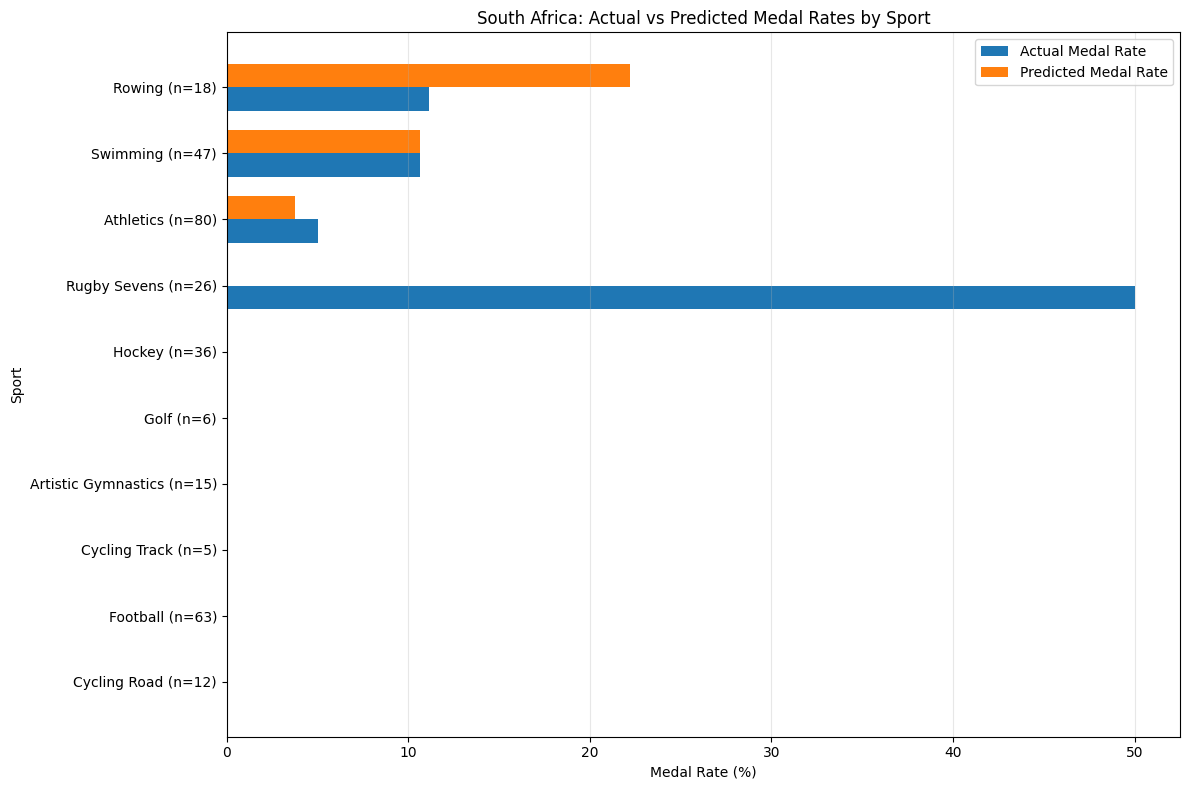

In [102]:
# Exclude sports with very few test observations
min_records = 5

sport_plot = sport_summary[
    sport_summary["Test_Records"] >= min_records
].copy()

# Select the 10 sports with the highest predicted medal rates
sport_plot = sport_plot.head(10)

# Reverse order for a more readable horizontal chart
sport_plot = sport_plot.sort_values(
    "Predicted_Medal_Rate"
)

plt.figure(figsize=(12, 8))

y = np.arange(len(sport_plot))
bar_height = 0.35

plt.barh(
    y - bar_height / 2,
    sport_plot["Actual_Medal_Rate"],
    bar_height,
    label="Actual Medal Rate"
)

plt.barh(
    y + bar_height / 2,
    sport_plot["Predicted_Medal_Rate"],
    bar_height,
    label="Predicted Medal Rate"
)

plt.yticks(
    y,
    [
        f"{sport} (n={count})"
        for sport, count in zip(
            sport_plot["Sport"],
            sport_plot["Test_Records"]
        )
    ]
)

plt.xlabel("Medal Rate (%)")
plt.ylabel("Sport")
plt.title(
    "South Africa: Actual vs Predicted Medal Rates by Sport"
)

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Graph showing predicted medal potential

The previous graph evaluates whether the model's predictions correspond with actual results. For your investment-related research question, I would also create a ranking of sports according to their average predicted medal probability.

This graph is useful because it shows how the model scores each sport before converting probabilities into Medal or No Medal classifications.


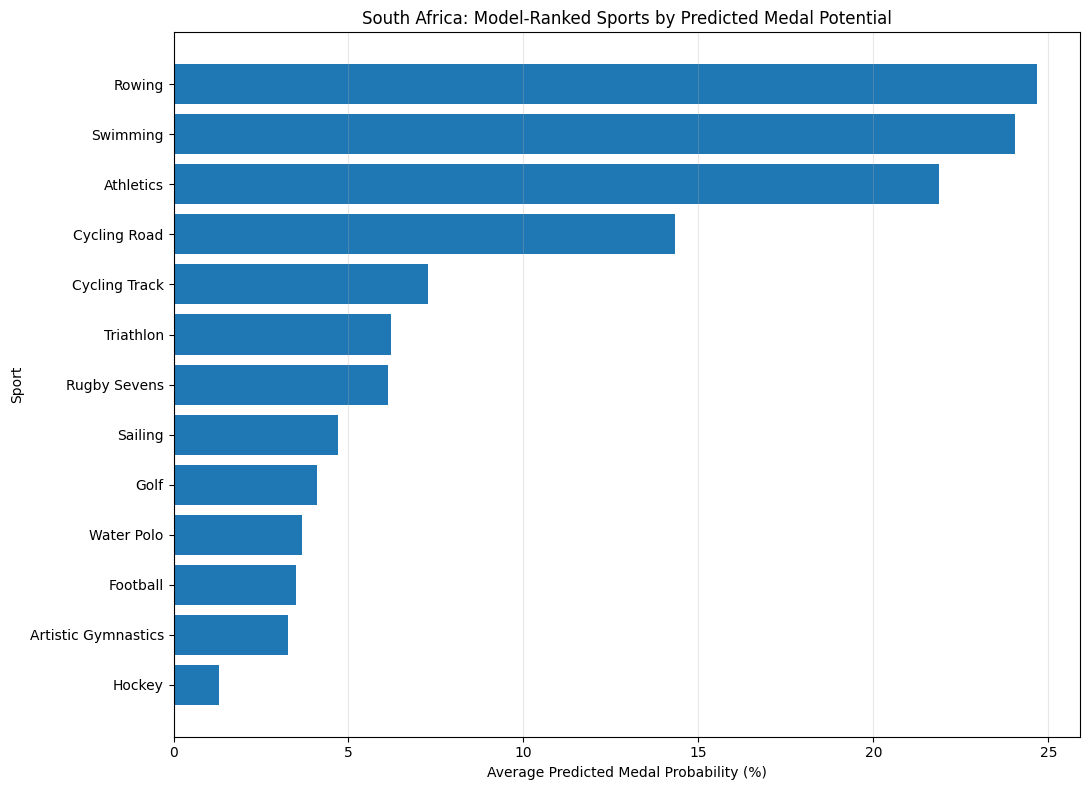

In [104]:
sport_potential = sport_summary[
    sport_summary["Test_Records"] >= min_records
].copy()

sport_potential = sport_potential.sort_values(
    by="Average_Medal_Probability",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    sport_potential["Sport"],
    sport_potential["Average_Medal_Probability"]
)

plt.xlabel("Average Predicted Medal Probability (%)")
plt.ylabel("Sport")

plt.title(
    "South Africa: Model-Ranked Sports by Predicted Medal Potential"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

###South African Olympic Medal Potential & Investment Analysis

####Stage A — Identification of High-Potential Sports

Based on the predictions from the South Africa Logistic Regression model, sports were evaluated across two primary metrics: Average Predicted Medal Probability and Actual vs. Predicted Medal Rates across athlete-event records ($n$).

####**Primary High-Potential Candidates**

**Rowing ($n = 18$)**

  - Model Rank & Probability: Ranks 1st overall with an average predicted probability of 24.7%.   

   - Predicted vs. Actual Performance: Demonstrates a predicted medal rate of 22.2% compared to an actual historical medal rate of 11.2%.   

  - Evaluation: Represents a strong, high-probability sport where the model identifies consistent podium potential across a moderate sample size.   

**Swimming ($n = 47$)**

   - Model Rank & Probability: Ranks 2nd overall with an average predicted probability of 24.0%.   

   - Predicted vs. Actual Performance: Exhibits nearly perfect calibration, with both predicted and actual medal rates aligned at 10.6%.   

  - Evaluation: Supported by a substantial sample size ($n = 47$), Swimming stands out as South Africa’s most consistent high-volume discipline with proven conversion from prediction to actual medal success.   

**Athletics ($n = 80$)**

  - Model Rank & Probability: Ranks 3rd overall with an average predicted probability of 21.9%.   

  - Predicted vs. Actual Performance: Shows an actual medal rate of ~5.0% against a predicted medal rate of 3.8%.  
  
  -  Evaluation: Features the largest sample size in the dataset ($n = 80$). The high average probability coupled with sustained historical medal conversion confirms Athletics as a core pillar of South African Olympic potential.

#### **Anomalies & Special Considerations**

Rugby Sevens ($n = 26$): Demonstrates an actual medal rate of 50.0% due to team-level podium finishes, yet holds a modest average predicted probability of ~6.1% and a predicted medal rate near 0%. This disparity stems from individual athlete-event recording structures in team sports, where a single team medal populates across all roster members.   

Cycling Road ($n = 12$) & Cycling Track ($n = 5$): Rank 4th and 5th in average predicted probability (~14.3% and ~7.3%, respectively), but have achieved 0.0% actual medal conversion in the test set. These high predictions reflect favorable athlete attribute profiles rather than proven historical outcomes.     

Based on the South African Linear regession models prediction which isnt a completely reliable forecast. The sport which South Africa has the highest chance of achieving medal yield in is rowing. This in itself doesnt mean that funds should be allocated to developing this sport but it could provide SASCOC with information which could be adapted in future exploratory audits.